# 📘 10.3 Physics-Informed Neural Networks
###

This notebook introduces Physics-Informed Neural Networks (PINNs), where the extent to which a system follows one or more governing equations is introduced as additional loss terms, penalising data that does not behave as expected.

### 🎯 Learning Objectives
> By the end of this notebook, you should be able to:
>
> * **Understand** the fundamental concept of Physics-Informed Neural Networks (PINNs) and how they differ from purely data-driven neural networks.
> * **Explain** the benefits of incorporating physical principles into machine learning models for improved robustness, generalization, and interpretability in engineering applications.
> * **Formulate** the loss function for a PINN, including terms for physics (governing equations), initial conditions, boundary conditions, and observed data.
> * **Explain** the role of collocation points in enforcing physical laws within the PINN framework.
> * **Analyze** the impact of weighting different loss terms (e.g., physics, IC, BC, data) on the PINN's training convergence and the accuracy of the predicted solution.
> * **Recognise** common challenges in PINN training, such as the tendency to converge to trivial solutions when physical constraints are insufficiently enforced or weighted.
> * **Apply** PINNs to solve both ordinary and partial differential equations, demonstrating how they can model physical systems.
> * **Utilise** PINNs to infer unknown physical parameters (e.g., thermal diffusivity) directly from data and the governing equations.
> * **Evaluate** the performance of PINNs in scenarios with limited or noisy data.

## 📂 10.3.0 How to use this notebook

This notebook extends the definition of a plain Neural Network to include physics information through the loss terms.

> ### 🧭 Theory preface
> In terms of theory, Physics-Informed Neural Networks (PINNs) are not substantially different from a plain neural network. Physics is included via a loss term, and it is important to understand how this results in competing loss terms that can either aid or hinder the training of a network, depending on the formulation.
>
> The purpose of this section is to make you aware of PINNs and help you explore how physics can be used to improve machine learning. At the end of this notebook, you should be aware of the benefits and challenges of PINNs and be able to train your own networks in PyTorch, with AI assistance to help provide the appropriate code syntax and PyTorch functions.

## 📂 10.3.1 Need for Physical Principles in Machine Learning

---

Data-driven models are emerging as an important new paradigm in engineering, built on the ready access to large data sets and the ability for models to learn to replicate patterns and trends in situations where inherent equations governing the system are either unknown or contain too many free variables for a straightforward solution. While these models can be used to *learn* the physics of a real system, there are often issues, such as:
* lack of generality to the trained model;
* lack of interpretability - little understanding why it works;
* overfitting;
* large data set requirements for training;
which limit the ability to apply results beyond situations where training data is available to cover the range of operating conditions.

Data required to operate/train models can also be contaminated by measurement noise, which, as you have seen in previous content on interpolation, can obscure the true physics.

From an engineering perspective, the overall goal of data-driven machine learning is to learn *physically interpretable* models that can be explained and confidently *generalized* and applied to a broad range of applications. Often these are spatio-temporal systems with a high dimensional state space $\mathbf{x}$, where specifically,

\begin{align}
\frac{d\mathbf{x}}{dt} &= \mathbf{f}(\mathbf{x},t,\Theta, \mathbf{w}_d),\\
\mathbf{y} &= \mathbf{h}(t,\mathbf{x}(t)) + \mathbf{w}_n,
\end{align}

where the dynamics of the system are set by the function $\mathbf{f}$, which depends on the present state, $\mathbf{x}$, time $t$, the parameters of the system, $\Theta$, and may include stochastic effects such as random fluctuations, represented by $\mathbf{w}_d$. $\mathbf{y}$ is the data from which the system will learn, which depends on the observations of the system represented by $\mathbf{h}$ and measurement noise, $\mathbf{w}_n$.

To do so we need to be able to infer $\mathbf{f}(\cdot)$ with parameters $\Theta$, from an array of measurements $\mathbf{y}$. Even relatively simple multi-scale or multi-physics systems present challenges, particularly if $\mathbf{h}(\cdot)$ only captures a finite range of states of the system, or when $\mathbf{w}_n$ is non-negligible.

A plain neural network tries to learn a mapping:
$$(t, x(t)) \longrightarrow x(t+\Delta t)$$
from data alone.

But dynamical systems are not arbitrary functions—they are constrained by:
* conservation laws
* stability regions
* smoothness and differentiability
* invariants (energy, mass, momentum)
* symmetries

A plain NN has no awareness of these constraints. It will happily learn a function that fits the training points but violates the dynamics everywhere else, hence the lack of generality. This is exactly why a plain NN can yield low loss but poor trajectories, as seen in Section 10.2.6.

In Notebook [10.2](https://colab.research.google.com/drive/1T-SwnrYrOgqTe4ceYH623QBAKmPgas0i?usp=sharing), the Neural ODE approach was a reasonable way to achieve what we might desire, but only for a basic ODE with perfect training data.

*What if we already knew some physical restraints on our system? Couldn't we use that knowledge to build a better model?*

## 📂 10.3.2 Physics-Informed Neural Networks (PINNs)

---

Physics-Informed Neural Networks (PINNs) are one of a range of methods that seek to overcome the limitations of Neural Networks by allowing users to build in a dependence on physical laws, as developed by Raissa, Perdikaris and Karniadakis (2019) [J. of Comp. Phys., vol. 378](https://doi.org/10.1016/j.jcp.2018.10.045).

The advantage of PINNs is that the concept behind them is relatively simple.

Consider a neural network which approximates the solution $x(t)$, where $u_θ(t)$ is the approximate solution for a given set of parameters $\theta$.

If we know that the temporal derivative of the solution follows the function,

$$ \frac{d x}{d t} = f(x,t),$$

we can define a residual, $\mathcal{R}$ as

$$\mathcal{R}(t; \theta) = \frac{du_\theta(t)}{dt}-f(u_\theta(t),t),$$

which represents how well the temporal derivative of the current output solution from the NN satisfies the known relationships for the temporal derivative of the system.

This allows us to evaluate the *physics loss* of the system as

$$\mathcal{L}_{phys}(\theta) = \frac{1}{N_{phys}}\sum^{N_{phys}}_{j=1}|\mathcal{R}(x_j,t_j;\theta)|^2,$$

as the average of the residual across all points in the solution domain.

The *Residual* is the instantaneous violation of the ODE/PDE, while the *Physics loss* is the mean-squared residual over all collocation points.

> ### ⚠️ Point of note
> A **collocation point** in a PINN is simply a point in the domain (in time, space, or both) where you force the neural network to satisfy the governing physics. It's where you “collocate” the differential equation and evaluate its residual.

As in a plain NN, you would also have training data for x(t), such that you also have a *data loss*

$$ \mathcal{L}_{data}(\theta) = \frac{1}{N_{data}}\sum^{N_{data}}_{i=1}\left(u_\theta(t_i)-x^{true}_i)\right)^2,$$

associated with the difference between the output of the NN and the training data.

In the case of a Physics-Informed Neural Network, these two losses are combined into a singular loss that the training will attempt to minimize, i.e.

$$\mathcal{L}_{total} = \mathcal{L}_{data} + \lambda \mathcal{L}_{phys},$$

where $\lambda$ weights the data loss against the physics loss.

> ### ⚠️ Point of note
> A *Physics-Informed Neural Network* is a neural network trained not only on data but also on the extent to which the solution matches governing relationships.

##  🧠 10.3.3 Weighting the Data and Physics Loss Terms

---

At first glance, it is reasonable to ask, if we know physical laws that govern the problem,

🧠 Why don't you enforce zero physics loss?

The reasons for this stem from the finite nature of the network and the requirement to approximate the true solution.

1.  **The NN often cannot represent the exact solution.**
    A neural network has a finite capacity (number of nodes, weights, and biases), and acts as an approximator.

    If the true solution *x*(*t*) is:
    -   stiff
    -   highly oscillatory
    -   has sharp gradients

    then the NN may not be expressive enough to represent it exactly.

2.  **The physics is only enforced at discrete collocation points.**

    PINNs do not enforce the ODE/PDE everywhere. They enforce it at a finite set of points. Even if the residual is zero at those points, it may not be zero in between.

3.  **Optimization may not find the global minimum.**

    Gradient descent will find a good minimum, but depending on the nature of the system, it may not find a perfect minimum.

4.  **Differentiation used to evaluate the ODE/PDEs introduces numerical error.**

    The derivative: du/dt from the NN output will be:
    *   floating-point
    *   approximate
    *   subject to roundoff and truncation errors

    So, even if the NN could represent the exact solution, the computed residual would not be exactly zero.

Even if you could exactly represent the true solution, there will generally be more than one solution that matches the required physics. In such cases, you need the true data to guide the solution to the appropriate physical dimensions and boundary conditions.

Training a PINN model requires minimizing the total Loss. This keeps PINNs relatively simple and close to a plain NN, but requires the user to determine the weighting between the data and physics.

The weighting between physics loss and data loss is one of the *most important* and *least trivial* design choices in PINNs. There is no universal value—the correct weighting depends on the problem and the scale of the residuals.

## 📂 10.3.4 A One-Dimensional PINN Example

---

Let's follow the example we used for our Neural ODE and see how we can use a PINN if we know that the system is governed by the ODE

$$\frac{dx}{dt} = x^3-x$$

In the Neural ODE from Notebook 10.2, we tried to learn this ODE and predict how the system would evolve from a specified initial condition $x_0$.

Knowing the true ODE, the aim is no longer to learn the ODE and integrate it to arrive at the trajectory $x(t,t_0)$, but instead to determine the trajectory directly based on the underlying ODE.

*Note:* This is done without any integration of the solution.

The PINN produces the output $u_\theta(t,x_0)$ across a series of points $t_i$, as an approximation to $x(t,t_0)$, based only on a specified series of time locations.

The PINN loss combines two terms:

---
**1. Physics Residual Loss**

This enforces the ODE at all collocation points $t_i$:

$$\mathcal{L}_{\text{phys}} = \frac{1}{N} \sum_{i=1}^{N}
\left(\frac{du_\theta}{dt}(t_i,x_0)-\left( u_\theta(t_i,x_0)^3 - u_\theta(t_i,x_0)\right)\right)^2.$$

---
**2. Initial Condition Loss**

This enforces the correct starting value:

$$\mathcal{L}_{\text{IC}} = \left( u_\theta(0,x_0) - x_0 \right)^2.$$

---
**Total PINN Loss**

$$ \mathcal{L} = \mathcal{L}_{\text{phys}} + \mathcal{L}_{\text{IC}}.$$

This loss ensures the neural network respects both the physics of the ODE and the initial conditions evenly.

To train the model, the system needs training data across the range of possible initial conditions and temporal domain.

Using device: cpu
Epoch 0, Loss = 0.538180
Epoch 500, Loss = 0.002109
Epoch 1000, Loss = 0.000574
Epoch 1500, Loss = 0.000257
Epoch 2000, Loss = 0.000203
Epoch 2500, Loss = 0.000176
Epoch 3000, Loss = 0.000116
Epoch 3500, Loss = 0.000034
Epoch 4000, Loss = 0.000003
Epoch 4500, Loss = 0.000001


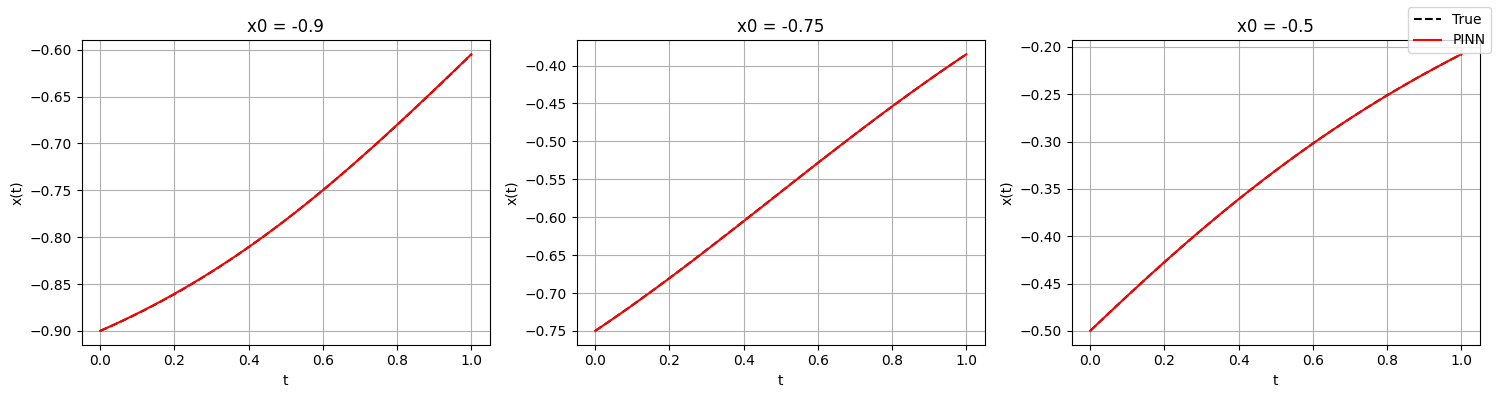

In [ ]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# ---------------------------------------------------------
# True ODE: dx/dt = x^3 - x
# ---------------------------------------------------------
def f_true(x):
    return x**3 - x

# ---------------------------------------------------------
# RK4 solver for generating true trajectories
# ---------------------------------------------------------
def generate_data(x0, T=1.0, steps=100):
    t = torch.linspace(0, T, steps, device=device)
    x = torch.zeros(steps, device=device)
    x[0] = x0
    dt = t[1] - t[0]
    for i in range(steps - 1):
        k1 = f_true(x[i])
        k2 = f_true(x[i] + dt*k1/2)
        k3 = f_true(x[i] + dt*k2/2)
        k4 = f_true(x[i] + dt*k3)
        x[i+1] = x[i] + dt*(k1 + 2*k2 + 2*k3 + k4)/6
    return t, x

# ---------------------------------------------------------
# PINN model: u(t, x0)
# ---------------------------------------------------------
class PINN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, 64),
            nn.Tanh(),
            nn.Linear(64, 64),
            nn.Tanh(),
            nn.Linear(64, 1)
        )

    def forward(self, t, x0):
        inp = torch.cat([t, x0], dim=1)   # shape [N,2]
        return self.net(inp)

pinn = PINN().to(device)

# ---------------------------------------------------------
# Training setup
# ---------------------------------------------------------
T = 1.0
steps = 100

# Time grid
t = torch.linspace(0, T, steps, device=device).unsqueeze(1)
t.requires_grad_(True)

# Multiple initial conditions
x0_vals = torch.tensor([-0.9, -0.75, -0.5, 0.5, 0.75, 0.9], device=device)

# Build (t, x0) grid
t_grid = t.repeat(len(x0_vals), 1)                     # shape [6*100, 1]
x0_grid = x0_vals.repeat_interleave(steps).unsqueeze(1)

opt = torch.optim.Adam(pinn.parameters(), lr=1e-3)

# ---------------------------------------------------------
# PINN training loop
# ---------------------------------------------------------
for epoch in range(5000):

    u = pinn(t_grid, x0_grid)                          # u(t, x0)

    du_dt = torch.autograd.grad(
        u, t_grid,
        grad_outputs=torch.ones_like(u),
        create_graph=True
    )[0]

    # Physics residual
    phys_res = du_dt - (u**3 - u)
    L_phys = (phys_res**2).mean()

    # Initial condition loss
    t0 = torch.zeros_like(x0_vals).unsqueeze(1)
    u0_pred = pinn(t0, x0_vals.unsqueeze(1))
    L_ic = ((u0_pred - x0_vals.unsqueeze(1))**2).mean()

    loss = L_phys + L_ic

    opt.zero_grad()
    loss.backward()
    opt.step()

    if epoch % 500 == 0:
        print(f"Epoch {epoch}, Loss = {loss.item():.6f}")

# ---------------------------------------------------------
# Compare PINN vs true ODE for 3 test initial conditions
# ---------------------------------------------------------
test_ics = [-0.9, -0.75, -0.5]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, x0 in zip(axes, test_ics):

    # True trajectory
    t_true, x_true = generate_data(torch.tensor(x0, device=device))

    # PINN prediction
    t_plot = t.detach().cpu()
    x0_plot = torch.full_like(t, x0, device=device)
    u_pred = pinn(t, x0_plot).detach().cpu().squeeze()

    ax.plot(t_true.cpu(), x_true.cpu(), 'k--', label='True')
    ax.plot(t_plot, u_pred, 'r', label='PINN')

    ax.set_title(f"x0 = {x0}")
    ax.set_xlabel("t")
    ax.set_ylabel("x(t)")
    ax.grid(True)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper right')

plt.tight_layout()
plt.show()


The PINNs has the advantage of already knowing the ODE, and with this we see that the PINN is able to construct a model with a small loss across the test data.


🧠 *How general is this solution?* How well will it do against different time series or intial conditions?



### Test the PINN Model on a New Time Grid - same initial condition

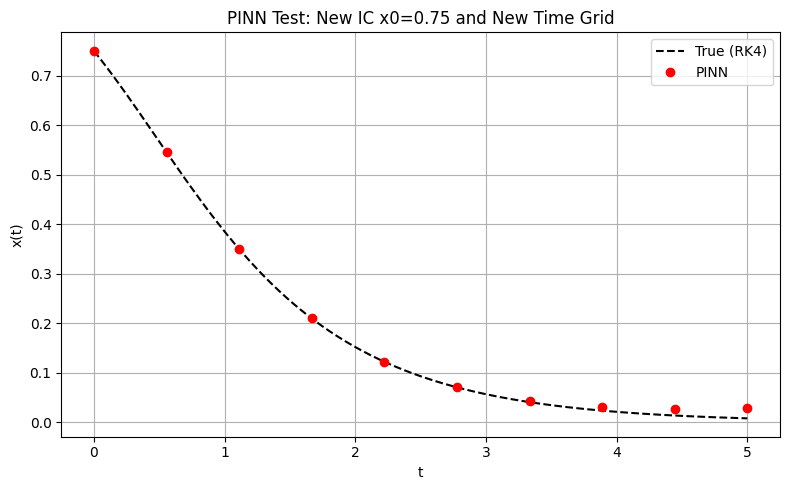

In [ ]:
# ---------------------------------------------------------
# Test the trained PINN on a new time grid
# ---------------------------------------------------------

# New initial condition (not in training set)
x0_test = torch.tensor([0.75], device=device)

# New time grid (different T, different number of steps)
T_test = 5.0
steps_test = 10
RKsteps_test = 1000
t_test = torch.linspace(0, T_test, steps_test, device=device).unsqueeze(1)
t_test.requires_grad_(False)   # no need for gradients during testing

# Build x0 grid for PINN
x0_test_grid = x0_test.repeat(steps_test).unsqueeze(1)

# PINN prediction
u_test = pinn(t_test, x0_test_grid).detach().cpu().squeeze()

# True trajectory using RK4
t_true, x_true = generate_data(x0_test, T=T_test, steps=RKsteps_test)

# Plot
plt.figure(figsize=(8,5))
plt.plot(t_true.cpu(), x_true.cpu(), 'k--', label='True (RK4)')
plt.plot(t_test.cpu(), u_test, 'ro', label='PINN')
plt.xlabel("t")
plt.ylabel("x(t)")
plt.title(f"PINN Test: New IC x0={x0_test.item()} and New Time Grid")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


Here we can see that a couple of advantages to the PINNs approach:
1. As we don't have to integrate the solution, we are able to use a much coarser time series than we had to manually integrate the known ODE as we did in Week 9.
2. The PINN does a good job of extrapolating beyond the range $t = [0,1]$ that it saw in training.

### Test the PINN Model on the Same Time Grid - Different Initial Condition

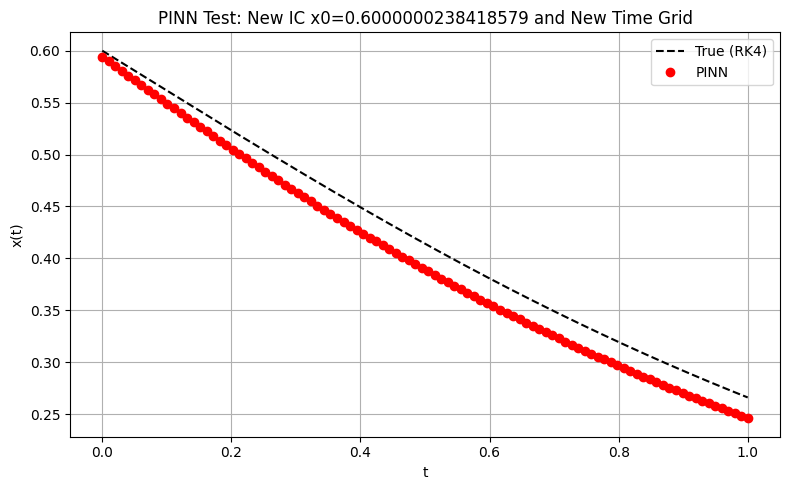

In [ ]:
# ---------------------------------------------------------
# Test the trained PINN on a new time grid
# ---------------------------------------------------------

# New initial condition (not in training set)
x0_test = torch.tensor([0.6], device=device)

# New time grid (different T, different number of steps)
T_test = 1.0
steps_test = 100
RKsteps_test = 1000
t_test = torch.linspace(0, T_test, steps_test, device=device).unsqueeze(1)
t_test.requires_grad_(False)   # no need for gradients during testing

# Build x0 grid for PINN
x0_test_grid = x0_test.repeat(steps_test).unsqueeze(1)

# PINN prediction
u_test = pinn(t_test, x0_test_grid).detach().cpu().squeeze()

# True trajectory using RK4
t_true, x_true = generate_data(x0_test, T=T_test, steps=RKsteps_test)

# Plot
plt.figure(figsize=(8,5))
plt.plot(t_true.cpu(), x_true.cpu(), 'k--', label='True (RK4)')
plt.plot(t_test.cpu(), u_test, 'ro', label='PINN')
plt.xlabel("t")
plt.ylabel("x(t)")
plt.title(f"PINN Test: New IC x0={x0_test.item()} and New Time Grid")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


In this respect, the PINN did worse under an unseen initial condition when compared to the Neural ODE.

The PINN needs to learn the entire solution field $x(t,x_0)$, compared to the Neural ODE which only needs to learn the ODE, $x^3-x$, and can then integrate.

In this case the training of the PINN is substantially faster, than the Neural ODE, so it would be realitively easy to increase the training domain to include more initial conditions.

## 📂 10.3.5 The Multi-Objective Optimisation Challenges of PINNs

---

While the inclusion of physics in a Neural Network can improve its performance via the addition of physical constraints and relationships, it also presents additional challenges to the training process.

Physics-Informed Neural Networks involve a fundamental tension: they must simultaneously satisfy data fidelity, boundary/initial conditions, and the governing differential equations. Each of these objectives pulls the optimization in a different direction. The PDE residual often lives on a very different numerical scale than the data loss, and boundary conditions can either be extremely stiff or under-constrained. Remember, the training of an NN is an optimization problem, which requires estimating gradients and following those to what is ideally a global minimum. When a system consists of multiple competing gradients, the optimizer is not descending a single smooth valley but navigating rugged terrain where improving one objective can easily worsen another. This is why PINNs frequently exhibit slow convergence, failure to learn sharp gradients, or collapse into trivial solutions that satisfy the PDE but ignore the data—or vice versa.

This is ultimately a multi-objective optimization problem disguised as a single loss function. When we combine losses with fixed scalar weights, we implicitly assume that all objectives are equally important and similarly scaled, which is almost never true. The PDE residual may dominate early training, preventing the network from learning the boundary conditions; later, the boundary loss may explode as the optimizer tries to correct earlier misalignment. Because the gradients of each objective can point in conflicting directions, the optimizer oscillates or becomes trapped in regions where no single descent direction improves all objectives. This is why techniques like adaptive loss weighting, curriculum training (IC → BC → PDE), pseudo-time stepping, or gradient-balancing methods (e.g., NTK-based scaling, GradNorm, or PINN-specific adaptive weights) are increasingly necessary. They acknowledge that PINNs are not a standard regression problem—they are a negotiation between competing physical constraints.

Effectively training a PINN is a bit of a 'dark art,' with a series of tricks that continue to be discovered and adapted. This section cannot cover all these approaches but will instead seek to demonstrate how these issues arise and how you can better recognize such problems in your own PINNs.

To gain an appreciation for these challenges, let's consider a one-dimensional rod, instrumented with a series of temperature sensors to provide the following data,

$$\left\{x_i, t_i, u^{meas}_i\right\}^{N_d}_{i=1}$$

where $x\in [0,1]$ is position along the rod, $t\in [0,T]$ is time, and $u_i$ is the measured temperature.

The temperature follows the 1D conduction equation (a partial differential equation)

$$\frac{\partial u}{\partial t} = \alpha\frac{\partial^2 u}{\partial x^2}.$$

Assume the aim is to estimate the temperature distribution along the rod as a function of time, where our experiment data is limited to a handful of positions along the rod, with associated measurement noise.

The goal of the NN is to learn the distribution $u_\theta = (x,t)$ as an approximation to the true temperature field.

To put some numbers to this, let's assume the rod has a known initial temperature distribution,

$$u(x,t=0) = \sin(\pi x),$$

and that the temperature at $x=0$ and $x=1$ remains fixed at $u(0,t)=0$ and $u(1,t)=0$ for all time.

In this case, the loss terms come from the physics, the known boundary condition, and the extent to which the solution matches the temperature sensor readings.

For this relatively basic problem, we already have four separate loss terms (if we count the two boundary conditions as a single loss term):

---
**1. Physics Residual Loss**

This enforces the PDE at all collocation points $t_i$:

$$\mathcal{L}_{\text{phys}} = \frac{1}{N} \sum_{i=1}^{N}
\left(\frac{du_\theta}{dt}(t_i,x_0)-\alpha \frac{\partial^2 u_\theta}{\partial x^2}(t_i,x_0)\right)^2.$$

---
**2. Boundary Condition Loss**

This enforces the known boundary condition at $x=1$ where $u=0$ for all time:

$$\mathcal{L}_{\text{BC1}} = \frac{1}{N_{BC}}\sum_i\left( u_\theta(1,t_i) - 0 \right)^2.$$

This enforces the unknown boundary condition at $x=0$ where $u=B_0$ for all time:

$$\mathcal{L}_{\text{BC0}} = \frac{1}{N_{BC}}\sum_i\left( u_\theta(0,t_i) - B_0 \right)^2.$$

---
**3. Data Loss**

This enforces the temperature sensor data at $[x_i, t_i]$:

$$\mathcal{L}_{\text{data}} = \frac{1}{N_{d}}\sum_i\left( u_\theta(x_i,t_i) - u^{meas}_i \right)^2.$$

---
**4. Initial Condition Loss**

This enforces the prescribed initial profile at $[x_i, 0]$:

$$\mathcal{L}_{\text{IC}} = \frac{1}{N_{IC}}\sum_i\left( u_\theta(x_i,0) - u_{\text{IC}(x_i)} \right)^2.$$

---
**Total PINN Loss**

$$ \mathcal{L} = \lambda_{phys}\cdot\mathcal{L}_{\text{phys}} + \lambda_{BC}\left(\mathcal{L}_{\text{BC0}} + \mathcal{L}_{\text{BC1}}\right) + \lambda_{data}\cdot\mathcal{L}_{\text{data}}+\lambda_{IC}\cdot\mathcal{L}_{\text{IC}}.$$

where $\lambda_{phys}, \lambda_{BC}, \lambda_{data}, \lambda_{IC}$ are weightings associated with each of the loss terms.

---
**The Spatio-Temporal Location of Collocation and Boundary Points**

The PINN works to minimize this combined loss term, but as we can see from the individual terms, the network needs to be evaluated at discrete points along the boundaries (in space and time) as well as points within the solution domain.
*   boundary points $x_{BC0}(0,t)$ - enforced at different times;
*   boundary points $x_{BC1}(1,t)$ - enforced at different times;
*   initial points $x_{IC}(x,0)$ - enforced at different $x$ at $t=0$;
*   data points $x_{data}(x,t)$ - sampled at different $x,t$ values;
*   physics points $x_{phys}(x,t)$ - sampled at different $x,t$ values.

The location of these points has the opportunity to introduce biases to the network. For this reason, it is common to use randomly seeded locations. In the example below, the collocation points, boundary condition points, and initial condition points are all generated randomly in time and/or location along the rod.

The present example considers 2000 collocation points for the physics, 200 points along each of the boundaries, 200 points at the initial condition, and data recorded at 4 fixed points along the rod $x=[0.2,0.4,0.6,0.8]$, at 300 random times.

### 🔹 Example Code Structure

The example code consists of 7 sections as follows:

1.  **Neural Network for u(x,t)**
    -   This sets the layers, neurons, and activation functions.
    -   In this case, the:
        -   input layer consists of 2 inputs into 64 neurons;
        -   hidden layer of 64 neurons;
        -   output layer of 64 neurons to a single output.
2.  **Collocation points (physics)**
    -   Randomly generates the collocation points at which the physics loss will be evaluated.
3.  **Initial condition u(x,0) = sin(pi x)**
    -   Randomly generates points along the rod at $t=0$ and sets the temperature at these points to $$u(x,0) = \sin(\pi x).$$
4.  **Boundary conditions**
    -   Randomly generate points at $x=0$ and $x=1$ and set temperature $u(0,t) = 0$ and $u(1,t) = 0$.
5.  **Real sensor data (example synthetic)**
    -   Generates synthetic data to represent experimental temperature measurements at four discrete locations at random times.
6.  **Training loop**
    -   Evaluates all the loss terms;
    -   Backpropagates loss to get loss gradients;
    -   Updates NN parameters.
7.  **Evaluate the trained PINN**
    -   Plots the predicted solution domain $u_{\theta}(x,t)$;
    -   Plots the loss terms vs. epoch to show how the training evolves;
    -   Plots the predicted solution against the analytical solution, below.

The synthetic data in this case corresponds to the analytical solution

$$u(x,t) = \sin(\pi x)e^{-\alpha \pi^2 t},$$

which corresponds to boundary conditions $u(0,t) = 0$ and $u(1,t)=0$.

### 🔹 PINNs Examples and Impact of Loss Terms

To start, let us see what happens when we apply equal weighting to the *boundary condition*, *initial condition*, and *physics* loss terms, i.e.,
$$\lambda_{phys}= \lambda_{BC}= \lambda_{IC} = 1, \qquad \lambda_{data}=0$$

You can click on `Show code` below to see exactly how the code has been structured.

Epoch 0, Loss=0.544364
Epoch 500, Loss=0.291886
Epoch 1000, Loss=0.076085
Epoch 1500, Loss=0.011959
Epoch 2000, Loss=0.002788
Epoch 2500, Loss=0.001147
Epoch 3000, Loss=0.000576
Epoch 3500, Loss=0.000296
Epoch 4000, Loss=0.000164
Epoch 4500, Loss=0.000108


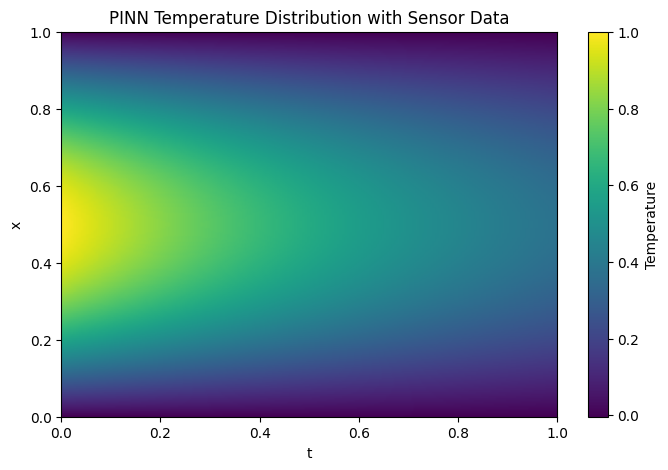

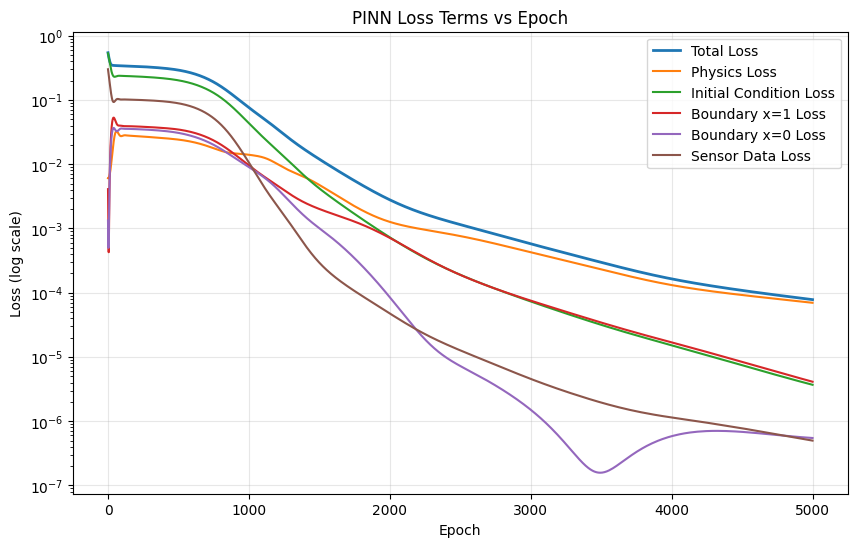

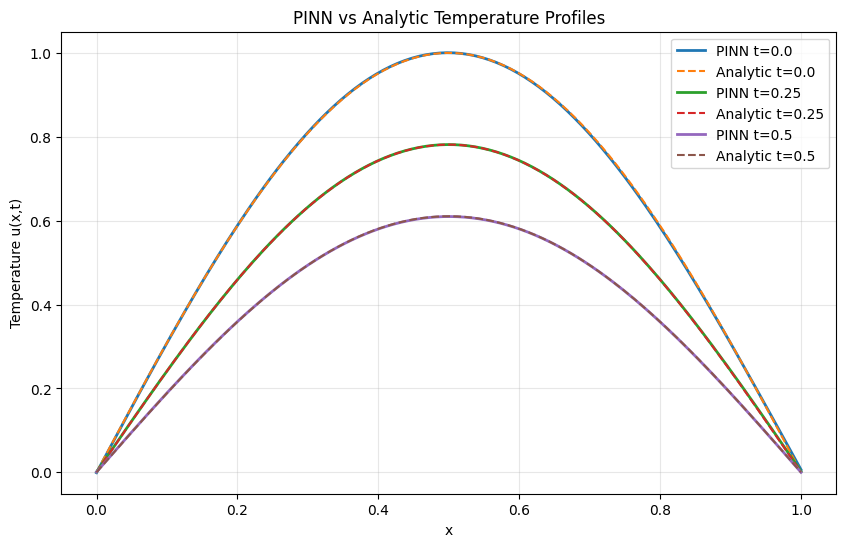

In [ ]:
# @title Simple Fixed Weight PINN for $\frac{du}{dt} = -\alpha\frac{\partial^2 u}{\partial x^2}$ with zero data weighting
# ---------------------------------------------------------
# Fixed weights
# ---------------------------------------------------------
lambda_phys   = 1.0 # @param {"type":"number"}
lambda_ic     = 1.0 # @param {"type":"number"}
lambda_bc0    = 1.0 # @param {"type":"number"}
lambda_bc1    = 1.0 # @param {"type":"number"}
lambda_data   = 0.0 # @param {"type":"number"}
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

device = "cuda" if torch.cuda.is_available() else "cpu"

# ---------------------------------------------------------
# 1. Neural Network for u(x,t)
# ---------------------------------------------------------
class PINN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, 64),
            nn.Tanh(),
            nn.Linear(64, 64),
            nn.Tanh(),
            nn.Linear(64, 1)
        )

    def forward(self, x, t):
        # Free NN output
        u_core = self.net(torch.cat([x, t], dim=1))
        return u_core

pinn = PINN().to(device)
optimizer = torch.optim.Adam([
    {"params": pinn.net.parameters(), "lr":1e-4}])

alpha = 0.1   # thermal diffusivity

# ---------------------------------------------------------
# 2. Collocation points (physics)
# ---------------------------------------------------------
N_f = 2000
x_f = torch.rand(N_f, 1, device=device)
t_f = torch.rand(N_f, 1, device=device)

# ---------------------------------------------------------
# 3. Initial condition u(x,0) = sin(pi x)
# ---------------------------------------------------------
N_ic = 200
x_ic = torch.rand(N_ic, 1, device=device)
t_ic = torch.zeros_like(x_ic)
u_ic = torch.sin(np.pi * x_ic)

# ---------------------------------------------------------
# 4. Boundary conditions
# ---------------------------------------------------------
N_bc = 200
t_bc = torch.rand(N_bc, 1, device=device)

x_bc1 = torch.ones_like(t_bc)      # u(1,t)=0
x_bc0 = torch.zeros_like(t_bc)     # u(0,t)=0

# ---------------------------------------------------------
# 5. Real sensor data (example synthetic)
# ---------------------------------------------------------
# 3 sensor positions (must be 1D!)
sensor_positions = torch.tensor([0.2, 0.4, 0.6, 0.8], device=device)

# 300 time samples
sensor_t_raw = torch.rand(300, device=device)

# Build full Cartesian grid (4 × 300 = 1200 samples)
X, T = torch.meshgrid(sensor_positions, sensor_t_raw, indexing='ij')

sensor_x = X.reshape(-1,1)
sensor_t = T.reshape(-1,1)

# Synthetic "real" data (replace with your CSV)
true_temp = torch.sin(np.pi * sensor_x) * torch.exp(-alpha * np.pi**2 * sensor_t)
# add 2% random noise to temperature sensors
sensor_u = true_temp #+ 0.02 * torch.randn_like(true_temp)

# Loss history
loss_history = {
    "total": [],
    "phys": [],
    "ic": [],
    "bc1": [],
    "bc0": [],
    "data": []
}


# ---------------------------------------------------------
# 6. Training loop
# ---------------------------------------------------------
def gradients(u, x):
    return torch.autograd.grad(u, x, grad_outputs=torch.ones_like(u),
                               create_graph=True)[0]

for epoch in range(5000):

    # PDE residual
    x_f.requires_grad_(True)
    t_f.requires_grad_(True)

    u_f = pinn(x_f, t_f)
    u_t = gradients(u_f, t_f)
    u_x = gradients(u_f, x_f)
    u_xx = gradients(u_x, x_f)

    L_phys = (u_t - alpha * u_xx).pow(2).mean()

    # Initial condition
    L_ic = (pinn(x_ic, t_ic) - u_ic).pow(2).mean()

    # Boundary x=1
    L_bc1 = pinn(x_bc1, t_bc).pow(2).mean()

    # Boundary x=0 (unknown)
    L_bc0 = pinn(x_bc0, t_bc).pow(2).mean()

    # Sensor data loss
    u_sensor_pred = pinn(sensor_x, sensor_t)
    L_data = (u_sensor_pred - sensor_u).pow(2).mean()

    # Total loss
    loss = (
        lambda_phys*L_phys
        + lambda_ic*L_ic
        + lambda_bc0*L_bc0
        + lambda_bc1*L_bc1
        + lambda_data*L_data)

    loss_history["total"].append(loss.item())
    loss_history["phys"].append(L_phys.item())
    loss_history["ic"].append(L_ic.item())
    loss_history["bc1"].append(L_bc1.item())
    loss_history["bc0"].append(L_bc0.item())
    loss_history["data"].append(L_data.item())

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if epoch % 500 == 0:
        print(f"Epoch {epoch}, Loss={loss.item():.6f}")

# ---------------------------------------------------------
# 7. Evaluate the trained PINN
# ---------------------------------------------------------
x_test = torch.linspace(0, 1, 200, device=device).unsqueeze(1)
t_test = torch.linspace(0, 1, 200, device=device).unsqueeze(1)

X, T = torch.meshgrid(x_test.squeeze(), t_test.squeeze(), indexing='ij')
u_pred = pinn(X.reshape(-1,1), T.reshape(-1,1)).detach().cpu().numpy()
U = u_pred.reshape(200,200)

plt.figure(figsize=(8,5))
plt.imshow(U, extent=[0,1,0,1], origin='lower', aspect='auto')
plt.colorbar(label="Temperature")
plt.xlabel("t")
plt.ylabel("x")
plt.title("PINN Temperature Distribution with Sensor Data")
plt.show()

def plot_loss_terms(loss_history):
    plt.figure(figsize=(10,6))

    plt.plot(loss_history["total"], label="Total Loss", linewidth=2)
    plt.plot(loss_history["phys"], label="Physics Loss")
    plt.plot(loss_history["ic"], label="Initial Condition Loss")
    plt.plot(loss_history["bc1"], label="Boundary x=1 Loss")
    plt.plot(loss_history["bc0"], label="Boundary x=0 Loss")
    plt.plot(loss_history["data"], label="Sensor Data Loss")

    plt.yscale("log")
    plt.xlabel("Epoch")
    plt.ylabel("Loss (log scale)")
    plt.title("PINN Loss Terms vs Epoch")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

plot_loss_terms(loss_history)

#device = next(pinn.parameters()).device

x = torch.linspace(0, 1, 200, device=device).unsqueeze(1)
times=[0.0, 0.25, 0.5]
plt.figure(figsize=(10,6))
for t in times:
    t_tensor = torch.full_like(x, t)

    # PINN prediction
    u_pred = pinn(x, t_tensor).detach().cpu().numpy().flatten()

    # Analytic solution
    u_true = np.sin(np.pi * x.cpu().numpy().flatten()) * np.exp(-alpha * np.pi**2 *t)

    # Plot
    plt.plot(x.cpu().numpy(), u_pred, label=f"PINN t={t}", linewidth=2)
    plt.plot(x.cpu().numpy(), u_true, '--', label=f"Analytic t={t}")

plt.xlabel("x")
plt.ylabel("Temperature u(x,t)")
plt.title("PINN vs Analytic Temperature Profiles")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()


We can see that for this problem, the initial condition, boundary condition, and physics are sufficient to provide a very good prediction of the true temperature field $u(x,t)$ without explicitly using any data in training. By looking at the individual loss terms, we can observe that even though the PINN is not being trained on the *data*, the term $\mathcal{L}_{data}$ is also decreasing. This indicates that the system is converging to a condition that aligns with the data.

> ### ⚠️ Point of note
> While we are enforcing the physics of this problem, we are not explicitly using finite differences or any implicit or explicit method to solve an ODE. Instead, we are using the PINN to solve for the entire field with a solution that does not depend on a specified grid.

***What role does each loss play?***

To better understand this, let's look at what happens if we remove the right boundary condition (*BC1*) from the optimization problem by setting $\lambda_{BC1}=0$, below.
$$\lambda_{phys}= \lambda_{BC0} = \lambda_{IC} = 1, \qquad \lambda_{data}= \lambda_{BC1}=0$$

Epoch 0, Loss=0.369605
Epoch 500, Loss=0.157293
Epoch 1000, Loss=0.084796
Epoch 1500, Loss=0.020902
Epoch 2000, Loss=0.002947
Epoch 2500, Loss=0.000750
Epoch 3000, Loss=0.000270
Epoch 3500, Loss=0.000145
Epoch 4000, Loss=0.000093
Epoch 4500, Loss=0.000065


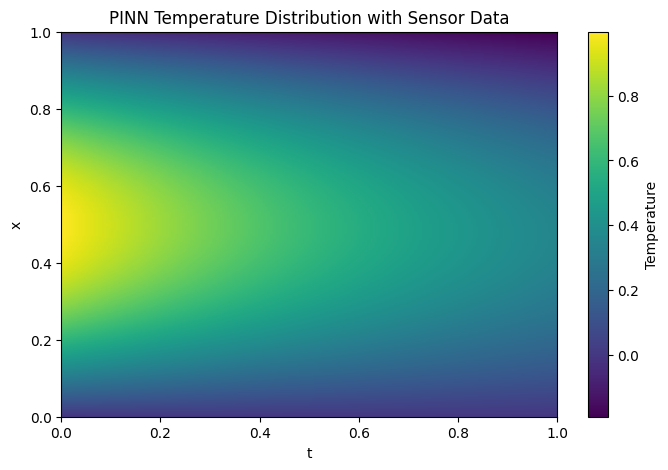

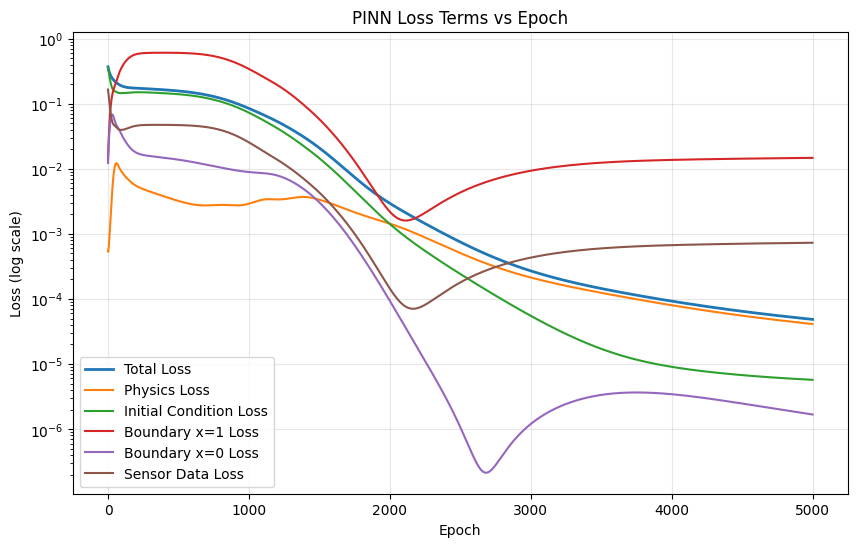

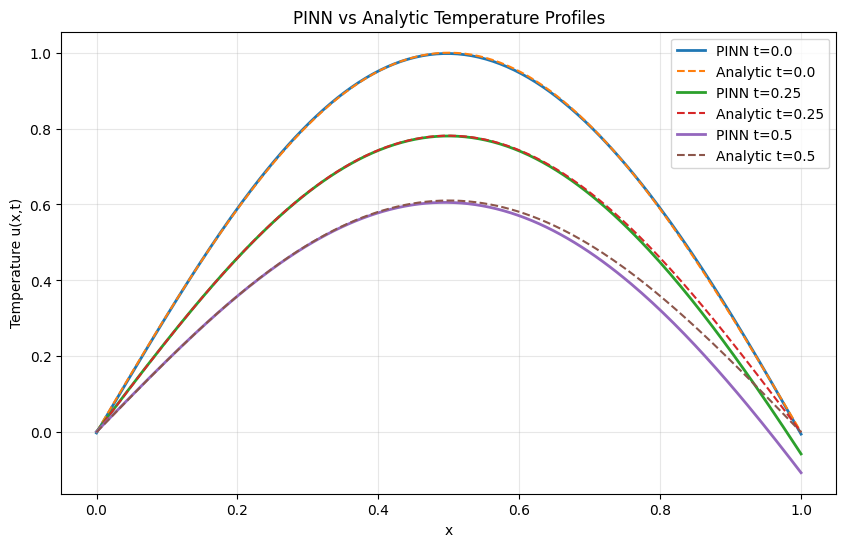

In [ ]:
# @title Simple Fixed Weight PINN for $\frac{du}{dt} = -\alpha\frac{\partial^2 u}{\partial x^2}$ with zero data weighting and only the left BC
# ---------------------------------------------------------
# Fixed weights
# ---------------------------------------------------------
lambda_phys   = 1.0 # @param {"type":"number"}
lambda_ic     = 1.0 # @param {"type":"number"}
lambda_bc0    = 1.0 # @param {"type":"number"}
lambda_bc1    = 0.0 # @param {"type":"number"}
lambda_data   = 0.0 # @param {"type":"number"}
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

device = "cuda" if torch.cuda.is_available() else "cpu"

# ---------------------------------------------------------
# 1. Neural Network for u(x,t)
# ---------------------------------------------------------
class PINN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, 64),
            nn.Tanh(),
            nn.Linear(64, 64),
            nn.Tanh(),
            nn.Linear(64, 1)
        )

    def forward(self, x, t):
        # Free NN output
        u_core = self.net(torch.cat([x, t], dim=1))
        return u_core

pinn = PINN().to(device)
optimizer = torch.optim.Adam([
    {"params": pinn.net.parameters(), "lr":1e-4}])

alpha = 0.1   # thermal diffusivity

# ---------------------------------------------------------
# 2. Collocation points (physics)
# ---------------------------------------------------------
N_f = 2000
x_f = torch.rand(N_f, 1, device=device)
t_f = torch.rand(N_f, 1, device=device)

# ---------------------------------------------------------
# 3. Initial condition u(x,0) = sin(pi x)
# ---------------------------------------------------------
N_ic = 200
x_ic = torch.rand(N_ic, 1, device=device)
t_ic = torch.zeros_like(x_ic)
u_ic = torch.sin(np.pi * x_ic)

# ---------------------------------------------------------
# 4. Boundary conditions
# ---------------------------------------------------------
N_bc = 200
t_bc = torch.rand(N_bc, 1, device=device)

x_bc1 = torch.ones_like(t_bc)      # u(1,t)=0
x_bc0 = torch.zeros_like(t_bc)     # u(0,t)=0

# ---------------------------------------------------------
# 5. Real sensor data (example synthetic)
# ---------------------------------------------------------
# 3 sensor positions (must be 1D!)
sensor_positions = torch.tensor([0.2, 0.4, 0.6, 0.8], device=device)

# 300 time samples
sensor_t_raw = torch.rand(300, device=device)

# Build full Cartesian grid (4 × 300 = 1200 samples)
X, T = torch.meshgrid(sensor_positions, sensor_t_raw, indexing='ij')

sensor_x = X.reshape(-1,1)
sensor_t = T.reshape(-1,1)

# Synthetic "real" data (replace with your CSV)
true_temp = torch.sin(np.pi * sensor_x) * torch.exp(-alpha * np.pi**2 * sensor_t)
# add 2% random noise to temperature sensors
sensor_u = true_temp #+ 0.02 * torch.randn_like(true_temp)

# Loss history
loss_history = {
    "total": [],
    "phys": [],
    "ic": [],
    "bc1": [],
    "bc0": [],
    "data": []
}


# ---------------------------------------------------------
# 6. Training loop
# ---------------------------------------------------------
def gradients(u, x):
    return torch.autograd.grad(u, x, grad_outputs=torch.ones_like(u),
                               create_graph=True)[0]

for epoch in range(5000):

    # PDE residual
    x_f.requires_grad_(True)
    t_f.requires_grad_(True)

    u_f = pinn(x_f, t_f)
    u_t = gradients(u_f, t_f)
    u_x = gradients(u_f, x_f)
    u_xx = gradients(u_x, x_f)

    L_phys = (u_t - alpha * u_xx).pow(2).mean()

    # Initial condition
    L_ic = (pinn(x_ic, t_ic) - u_ic).pow(2).mean()

    # Boundary x=1
    L_bc1 = pinn(x_bc1, t_bc).pow(2).mean()

    # Boundary x=0 (unknown)
    L_bc0 = pinn(x_bc0, t_bc).pow(2).mean()

    # Sensor data loss
    u_sensor_pred = pinn(sensor_x, sensor_t)
    L_data = (u_sensor_pred - sensor_u).pow(2).mean()

    # Total loss
    loss = (
        lambda_phys*L_phys
        + lambda_ic*L_ic
        + lambda_bc0*L_bc0
        + lambda_bc1*L_bc1
        + lambda_data*L_data)

    loss_history["total"].append(loss.item())
    loss_history["phys"].append(L_phys.item())
    loss_history["ic"].append(L_ic.item())
    loss_history["bc1"].append(L_bc1.item())
    loss_history["bc0"].append(L_bc0.item())
    loss_history["data"].append(L_data.item())

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if epoch % 500 == 0:
        print(f"Epoch {epoch}, Loss={loss.item():.6f}")

# ---------------------------------------------------------
# 7. Evaluate the trained PINN
# ---------------------------------------------------------
x_test = torch.linspace(0, 1, 200, device=device).unsqueeze(1)
t_test = torch.linspace(0, 1, 200, device=device).unsqueeze(1)

X, T = torch.meshgrid(x_test.squeeze(), t_test.squeeze(), indexing='ij')
u_pred = pinn(X.reshape(-1,1), T.reshape(-1,1)).detach().cpu().numpy()
U = u_pred.reshape(200,200)

plt.figure(figsize=(8,5))
plt.imshow(U, extent=[0,1,0,1], origin='lower', aspect='auto')
plt.colorbar(label="Temperature")
plt.xlabel("t")
plt.ylabel("x")
plt.title("PINN Temperature Distribution with Sensor Data")
plt.show()

def plot_loss_terms(loss_history):
    plt.figure(figsize=(10,6))

    plt.plot(loss_history["total"], label="Total Loss", linewidth=2)
    plt.plot(loss_history["phys"], label="Physics Loss")
    plt.plot(loss_history["ic"], label="Initial Condition Loss")
    plt.plot(loss_history["bc1"], label="Boundary x=1 Loss")
    plt.plot(loss_history["bc0"], label="Boundary x=0 Loss")
    plt.plot(loss_history["data"], label="Sensor Data Loss")

    plt.yscale("log")
    plt.xlabel("Epoch")
    plt.ylabel("Loss (log scale)")
    plt.title("PINN Loss Terms vs Epoch")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

plot_loss_terms(loss_history)

#device = next(pinn.parameters()).device

x = torch.linspace(0, 1, 200, device=device).unsqueeze(1)
times=[0.0, 0.25, 0.5]
plt.figure(figsize=(10,6))
for t in times:
    t_tensor = torch.full_like(x, t)

    # PINN prediction
    u_pred = pinn(x, t_tensor).detach().cpu().numpy().flatten()

    # Analytic solution
    u_true = np.sin(np.pi * x.cpu().numpy().flatten()) * np.exp(-alpha * np.pi**2 *t)

    # Plot
    plt.plot(x.cpu().numpy(), u_pred, label=f"PINN t={t}", linewidth=2)
    plt.plot(x.cpu().numpy(), u_true, '--', label=f"Analytic t={t}")

plt.xlabel("x")
plt.ylabel("Temperature u(x,t)")
plt.title("PINN vs Analytic Temperature Profiles")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()


Here, we can observe that without enforcing the right boundary condition and without including the data, the system satisfies the physics with a solution that does not match the specified boundary conditions or the provided data, as evidenced by $\mathcal{L}_{data}$ only dropping to approximately $10^{-3}$.

### ***What happens if we turn off the loss associated with the initial condition?***
$$\lambda_{phys}= \lambda_{BC0,1} = 1, \qquad \lambda_{data}= \lambda_{IC}=0$$

Epoch 0, Loss=0.065157
Epoch 500, Loss=0.000015
Epoch 1000, Loss=0.000009
Epoch 1500, Loss=0.000007
Epoch 2000, Loss=0.000005
Epoch 2500, Loss=0.000003
Epoch 3000, Loss=0.000002
Epoch 3500, Loss=0.000001
Epoch 4000, Loss=0.000001
Epoch 4500, Loss=0.000000


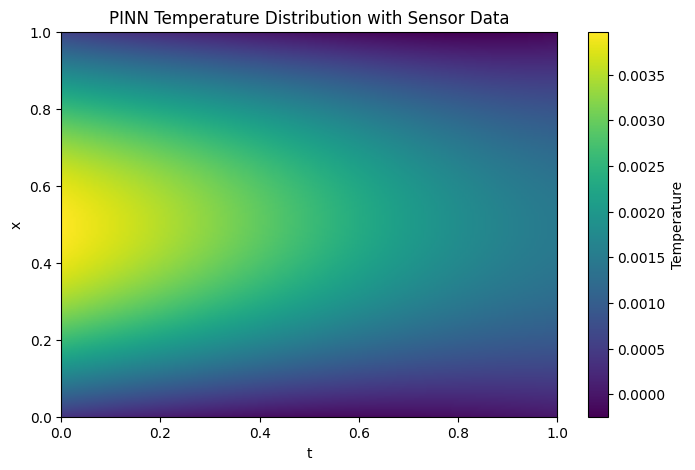

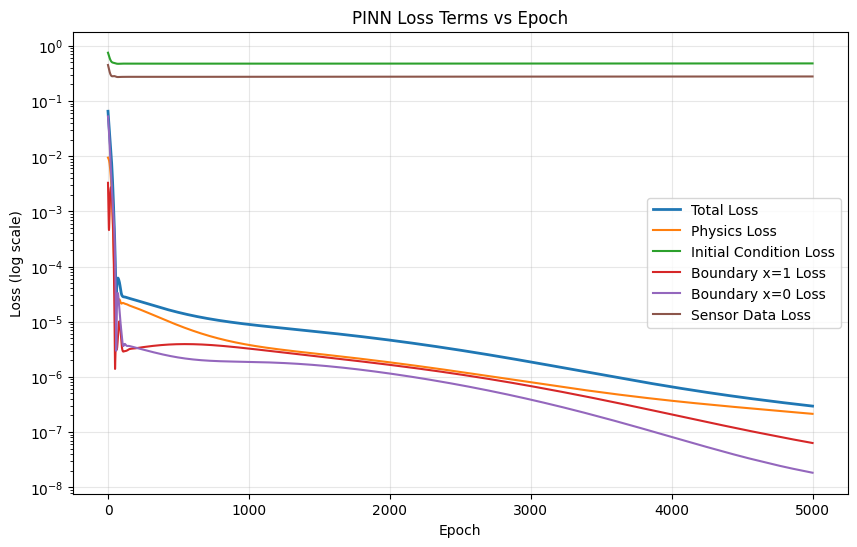

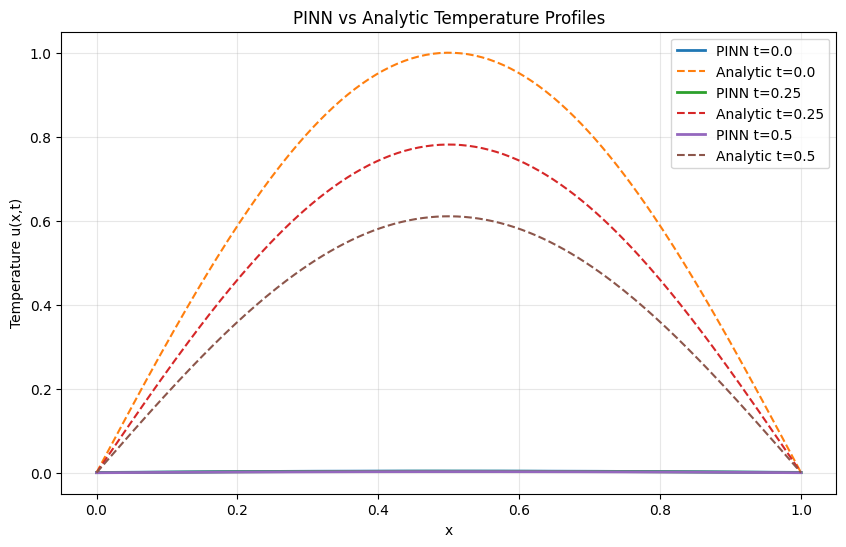

In [ ]:
# @title Simple Fixed Weight PINN for $\frac{du}{dt} = -\alpha\frac{\partial^2 u}{\partial x^2}$ with zero data and IC weighting
# ---------------------------------------------------------
# Fixed weights
# ---------------------------------------------------------
lambda_phys   = 1.0 # @param {"type":"number"}
lambda_ic     = 0.0 # @param {"type":"number"}
lambda_bc0    = 1.0 # @param {"type":"number"}
lambda_bc1    = 1.0 # @param {"type":"number"}
lambda_data   = 0.0 # @param {"type":"number"}
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

device = "cuda" if torch.cuda.is_available() else "cpu"

# ---------------------------------------------------------
# 1. Neural Network for u(x,t)
# ---------------------------------------------------------
class PINN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, 64),
            nn.Tanh(),
            nn.Linear(64, 64),
            nn.Tanh(),
            nn.Linear(64, 1)
        )

    def forward(self, x, t):
        # Free NN output
        u_core = self.net(torch.cat([x, t], dim=1))
        return u_core

pinn = PINN().to(device)
optimizer = torch.optim.Adam([
    {"params": pinn.net.parameters(), "lr":1e-4}])

alpha = 0.1   # thermal diffusivity

# ---------------------------------------------------------
# 2. Collocation points (physics)
# ---------------------------------------------------------
N_f = 2000
x_f = torch.rand(N_f, 1, device=device)
t_f = torch.rand(N_f, 1, device=device)

# ---------------------------------------------------------
# 3. Initial condition u(x,0) = sin(pi x)
# ---------------------------------------------------------
N_ic = 200
x_ic = torch.rand(N_ic, 1, device=device)
t_ic = torch.zeros_like(x_ic)
u_ic = torch.sin(np.pi * x_ic)

# ---------------------------------------------------------
# 4. Boundary conditions
# ---------------------------------------------------------
N_bc = 200
t_bc = torch.rand(N_bc, 1, device=device)

x_bc1 = torch.ones_like(t_bc)      # u(1,t)=0
x_bc0 = torch.zeros_like(t_bc)     # u(0,t)=0

# ---------------------------------------------------------
# 5. Real sensor data (example synthetic)
# ---------------------------------------------------------
# 3 sensor positions (must be 1D!)
sensor_positions = torch.tensor([0.2, 0.4, 0.6, 0.8], device=device)

# 300 time samples
sensor_t_raw = torch.rand(300, device=device)

# Build full Cartesian grid (4 × 300 = 1200 samples)
X, T = torch.meshgrid(sensor_positions, sensor_t_raw, indexing='ij')

sensor_x = X.reshape(-1,1)
sensor_t = T.reshape(-1,1)

# Synthetic "real" data (replace with your CSV)
true_temp = torch.sin(np.pi * sensor_x) * torch.exp(-alpha * np.pi**2 * sensor_t)
# add 2% random noise to temperature sensors
sensor_u = true_temp #+ 0.02 * torch.randn_like(true_temp)

# Loss history
loss_history = {
    "total": [],
    "phys": [],
    "ic": [],
    "bc1": [],
    "bc0": [],
    "data": []
}


# ---------------------------------------------------------
# 6. Training loop
# ---------------------------------------------------------
def gradients(u, x):
    return torch.autograd.grad(u, x, grad_outputs=torch.ones_like(u),
                               create_graph=True)[0]

for epoch in range(5000):

    # PDE residual
    x_f.requires_grad_(True)
    t_f.requires_grad_(True)

    u_f = pinn(x_f, t_f)
    u_t = gradients(u_f, t_f)
    u_x = gradients(u_f, x_f)
    u_xx = gradients(u_x, x_f)

    L_phys = (u_t - alpha * u_xx).pow(2).mean()

    # Initial condition
    L_ic = (pinn(x_ic, t_ic) - u_ic).pow(2).mean()

    # Boundary x=1
    L_bc1 = pinn(x_bc1, t_bc).pow(2).mean()

    # Boundary x=0 (unknown)
    L_bc0 = pinn(x_bc0, t_bc).pow(2).mean()

    # Sensor data loss
    u_sensor_pred = pinn(sensor_x, sensor_t)
    L_data = (u_sensor_pred - sensor_u).pow(2).mean()

    # Total loss
    loss = (
        lambda_phys*L_phys
        + lambda_ic*L_ic
        + lambda_bc0*L_bc0
        + lambda_bc1*L_bc1
        + lambda_data*L_data)

    loss_history["total"].append(loss.item())
    loss_history["phys"].append(L_phys.item())
    loss_history["ic"].append(L_ic.item())
    loss_history["bc1"].append(L_bc1.item())
    loss_history["bc0"].append(L_bc0.item())
    loss_history["data"].append(L_data.item())

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if epoch % 500 == 0:
        print(f"Epoch {epoch}, Loss={loss.item():.6f}")

# ---------------------------------------------------------
# 7. Evaluate the trained PINN
# ---------------------------------------------------------
x_test = torch.linspace(0, 1, 200, device=device).unsqueeze(1)
t_test = torch.linspace(0, 1, 200, device=device).unsqueeze(1)

X, T = torch.meshgrid(x_test.squeeze(), t_test.squeeze(), indexing='ij')
u_pred = pinn(X.reshape(-1,1), T.reshape(-1,1)).detach().cpu().numpy()
U = u_pred.reshape(200,200)

plt.figure(figsize=(8,5))
plt.imshow(U, extent=[0,1,0,1], origin='lower', aspect='auto')
plt.colorbar(label="Temperature")
plt.xlabel("t")
plt.ylabel("x")
plt.title("PINN Temperature Distribution with Sensor Data")
plt.show()

def plot_loss_terms(loss_history):
    plt.figure(figsize=(10,6))

    plt.plot(loss_history["total"], label="Total Loss", linewidth=2)
    plt.plot(loss_history["phys"], label="Physics Loss")
    plt.plot(loss_history["ic"], label="Initial Condition Loss")
    plt.plot(loss_history["bc1"], label="Boundary x=1 Loss")
    plt.plot(loss_history["bc0"], label="Boundary x=0 Loss")
    plt.plot(loss_history["data"], label="Sensor Data Loss")

    plt.yscale("log")
    plt.xlabel("Epoch")
    plt.ylabel("Loss (log scale)")
    plt.title("PINN Loss Terms vs Epoch")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

plot_loss_terms(loss_history)

#device = next(pinn.parameters()).device

x = torch.linspace(0, 1, 200, device=device).unsqueeze(1)
times=[0.0, 0.25, 0.5]
plt.figure(figsize=(10,6))
for t in times:
    t_tensor = torch.full_like(x, t)

    # PINN prediction
    u_pred = pinn(x, t_tensor).detach().cpu().numpy().flatten()

    # Analytic solution
    u_true = np.sin(np.pi * x.cpu().numpy().flatten()) * np.exp(-alpha * np.pi**2 *t)

    # Plot
    plt.plot(x.cpu().numpy(), u_pred, label=f"PINN t={t}", linewidth=2)
    plt.plot(x.cpu().numpy(), u_true, '--', label=f"Analytic t={t}")

plt.xlabel("x")
plt.ylabel("Temperature u(x,t)")
plt.title("PINN vs Analytic Temperature Profiles")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()


In the absence of needing to satisfy any known initial condition, the network has determined that the easiest way to satisfy the governing physics is to drive toward the *trivial solution* $u(x,t) = 0$.

The trivial zero solution is the single most attractive “energy minimum” in many PINN setups, and the optimizer will happily fall into it unless you explicitly prevent it. The reason is structural: for a huge class of PDEs, especially diffusion-type equations like the heat equation, $u = 0$ satisfies the PDE perfectly. If your loss contains a physics term like

$$ L_{\text{phys}} = \left\|\frac{du}{dt} - \alpha \frac{\partial^2 u}{\partial x^2}\right\|^2, $$

then $u = 0$ makes this entire term exactly zero. If your initial-condition and boundary-condition losses are weak, poorly weighted, noisy, or not enforced early enough, the optimizer discovers that collapsing the network output toward zero gives it a very low total loss.

In other words, the PDE itself does not push the solution away from zero—only the IC/BC/data terms do, and if they are not dominant, the PINN drifts toward the trivial solution.

In this case, the BCs are zero, so in the absence of the data term, this trivial solution $u=0$ is only constrained by the ICs.

***What happens if we have limited data (i.e., values at four points along the rod) but don't enforce physics?***
Without data, there is nothing to make the solution evolve past the initial condition.
$$\lambda_{IC}= \lambda_{BC0,1} = \lambda_{data}=1, \qquad \lambda_{phys}=0$$

Epoch 0, Loss=1.213871
Epoch 500, Loss=0.319063
Epoch 1000, Loss=0.269433
Epoch 1500, Loss=0.086365
Epoch 2000, Loss=0.017780
Epoch 2500, Loss=0.005688
Epoch 3000, Loss=0.001244
Epoch 3500, Loss=0.000643
Epoch 4000, Loss=0.000381
Epoch 4500, Loss=0.000224


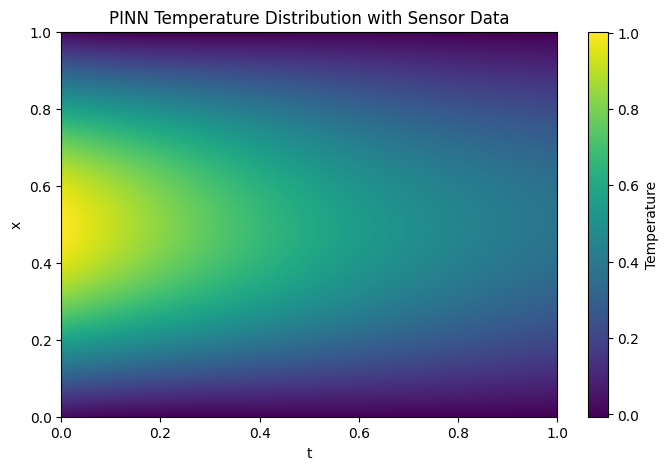

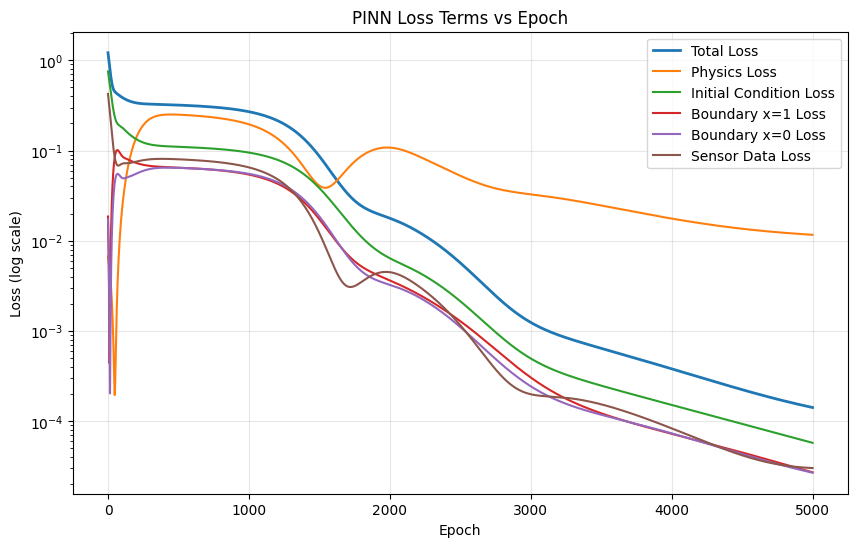

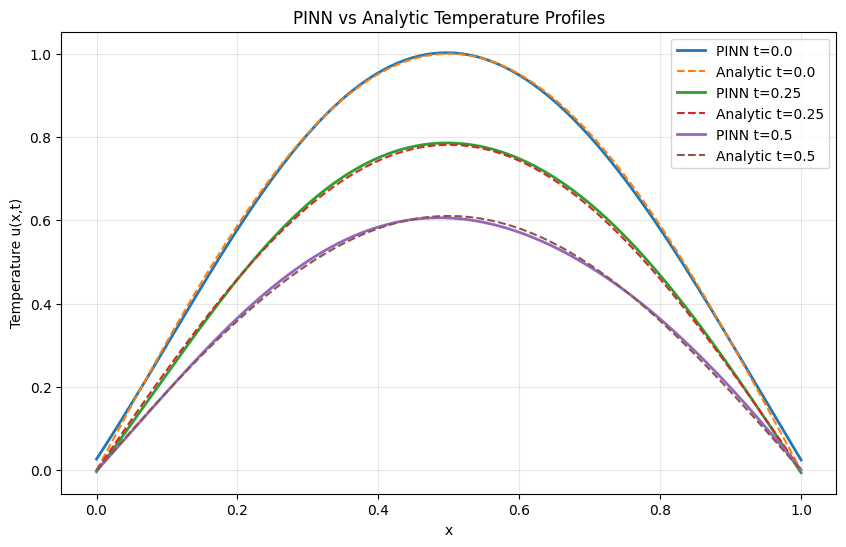

In [ ]:
# @title Simple Fixed Weight PINN for $\frac{du}{dt} = -\alpha\frac{\partial^2 u}{\partial x^2}$ with data but no physics
# ---------------------------------------------------------
# Fixed weights
# ---------------------------------------------------------
lambda_phys   = 0.0 # @param {"type":"number"}
lambda_ic     = 1.0 # @param {"type":"number"}
lambda_bc0    = 1.0 # @param {"type":"number"}
lambda_bc1    = 1.0 # @param {"type":"number"}
lambda_data   = 1.0 # @param {"type":"number"}
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

device = "cuda" if torch.cuda.is_available() else "cpu"

# ---------------------------------------------------------
# 1. Neural Network for u(x,t)
# ---------------------------------------------------------
class PINN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, 64),
            nn.Tanh(),
            nn.Linear(64, 64),
            nn.Tanh(),
            nn.Linear(64, 1)
        )

    def forward(self, x, t):
        # Free NN output
        u_core = self.net(torch.cat([x, t], dim=1))
        return u_core

pinn = PINN().to(device)
optimizer = torch.optim.Adam([
    {"params": pinn.net.parameters(), "lr":1e-4}])

alpha = 0.1   # thermal diffusivity

# ---------------------------------------------------------
# 2. Collocation points (physics)
# ---------------------------------------------------------
N_f = 2000
x_f = torch.rand(N_f, 1, device=device)
t_f = torch.rand(N_f, 1, device=device)

# ---------------------------------------------------------
# 3. Initial condition u(x,0) = sin(pi x)
# ---------------------------------------------------------
N_ic = 200
x_ic = torch.rand(N_ic, 1, device=device)
t_ic = torch.zeros_like(x_ic)
u_ic = torch.sin(np.pi * x_ic)

# ---------------------------------------------------------
# 4. Boundary conditions
# ---------------------------------------------------------
N_bc = 200
t_bc = torch.rand(N_bc, 1, device=device)

x_bc1 = torch.ones_like(t_bc)      # u(1,t)=0
x_bc0 = torch.zeros_like(t_bc)     # u(0,t)=0

# ---------------------------------------------------------
# 5. Real sensor data (example synthetic)
# ---------------------------------------------------------
# 3 sensor positions (must be 1D!)
sensor_positions = torch.tensor([0.2, 0.4, 0.6, 0.8], device=device)

# 300 time samples
sensor_t_raw = torch.rand(300, device=device)

# Build full Cartesian grid (4 × 300 = 1200 samples)
X, T = torch.meshgrid(sensor_positions, sensor_t_raw, indexing='ij')

sensor_x = X.reshape(-1,1)
sensor_t = T.reshape(-1,1)

# Synthetic "real" data (replace with your CSV)
true_temp = torch.sin(np.pi * sensor_x) * torch.exp(-alpha * np.pi**2 * sensor_t)
# add 2% random noise to temperature sensors
sensor_u = true_temp #+ 0.02 * torch.randn_like(true_temp)

# Loss history
loss_history = {
    "total": [],
    "phys": [],
    "ic": [],
    "bc1": [],
    "bc0": [],
    "data": []
}


# ---------------------------------------------------------
# 6. Training loop
# ---------------------------------------------------------
def gradients(u, x):
    return torch.autograd.grad(u, x, grad_outputs=torch.ones_like(u),
                               create_graph=True)[0]

for epoch in range(5000):

    # PDE residual
    x_f.requires_grad_(True)
    t_f.requires_grad_(True)

    u_f = pinn(x_f, t_f)
    u_t = gradients(u_f, t_f)
    u_x = gradients(u_f, x_f)
    u_xx = gradients(u_x, x_f)

    L_phys = (u_t - alpha * u_xx).pow(2).mean()

    # Initial condition
    L_ic = (pinn(x_ic, t_ic) - u_ic).pow(2).mean()

    # Boundary x=1
    L_bc1 = pinn(x_bc1, t_bc).pow(2).mean()

    # Boundary x=0 (unknown)
    L_bc0 = pinn(x_bc0, t_bc).pow(2).mean()

    # Sensor data loss
    u_sensor_pred = pinn(sensor_x, sensor_t)
    L_data = (u_sensor_pred - sensor_u).pow(2).mean()

    # Total loss
    loss = (
        lambda_phys*L_phys
        + lambda_ic*L_ic
        + lambda_bc0*L_bc0
        + lambda_bc1*L_bc1
        + lambda_data*L_data)

    loss_history["total"].append(loss.item())
    loss_history["phys"].append(L_phys.item())
    loss_history["ic"].append(L_ic.item())
    loss_history["bc1"].append(L_bc1.item())
    loss_history["bc0"].append(L_bc0.item())
    loss_history["data"].append(L_data.item())

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if epoch % 500 == 0:
        print(f"Epoch {epoch}, Loss={loss.item():.6f}")

# ---------------------------------------------------------
# 7. Evaluate the trained PINN
# ---------------------------------------------------------
x_test = torch.linspace(0, 1, 200, device=device).unsqueeze(1)
t_test = torch.linspace(0, 1, 200, device=device).unsqueeze(1)

X, T = torch.meshgrid(x_test.squeeze(), t_test.squeeze(), indexing='ij')
u_pred = pinn(X.reshape(-1,1), T.reshape(-1,1)).detach().cpu().numpy()
U = u_pred.reshape(200,200)

plt.figure(figsize=(8,5))
plt.imshow(U, extent=[0,1,0,1], origin='lower', aspect='auto')
plt.colorbar(label="Temperature")
plt.xlabel("t")
plt.ylabel("x")
plt.title("PINN Temperature Distribution with Sensor Data")
plt.show()

def plot_loss_terms(loss_history):
    plt.figure(figsize=(10,6))

    plt.plot(loss_history["total"], label="Total Loss", linewidth=2)
    plt.plot(loss_history["phys"], label="Physics Loss")
    plt.plot(loss_history["ic"], label="Initial Condition Loss")
    plt.plot(loss_history["bc1"], label="Boundary x=1 Loss")
    plt.plot(loss_history["bc0"], label="Boundary x=0 Loss")
    plt.plot(loss_history["data"], label="Sensor Data Loss")

    plt.yscale("log")
    plt.xlabel("Epoch")
    plt.ylabel("Loss (log scale)")
    plt.title("PINN Loss Terms vs Epoch")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

plot_loss_terms(loss_history)

#device = next(pinn.parameters()).device

x = torch.linspace(0, 1, 200, device=device).unsqueeze(1)
times=[0.0, 0.25, 0.5]
plt.figure(figsize=(10,6))
for t in times:
    t_tensor = torch.full_like(x, t)

    # PINN prediction
    u_pred = pinn(x, t_tensor).detach().cpu().numpy().flatten()

    # Analytic solution
    u_true = np.sin(np.pi * x.cpu().numpy().flatten()) * np.exp(-alpha * np.pi**2 *t)

    # Plot
    plt.plot(x.cpu().numpy(), u_pred, label=f"PINN t={t}", linewidth=2)
    plt.plot(x.cpu().numpy(), u_true, '--', label=f"Analytic t={t}")

plt.xlabel("x")
plt.ylabel("Temperature u(x,t)")
plt.title("PINN vs Analytic Temperature Profiles")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()


With the physics turned off, this becomes similar to a plain neural network. Its ability to learn the correct solution depends on the quality and density of the data it is trained on. With data distributed across four points, we achieve a reasonable solution, but it is clearly not as accurate as the one that includes physics.

## 📂 10.3.6 Using PINNs to Combine Real Data with Physics

Let's now look at how PINNs can be used to combine real data with existing understanding of underlying physics to infer unknown parameters or reconstruct missing regions.

Consider the one-dimensional rod from section 10.3.5, where the temperature follows the 1D conduction equation (a partial differential equation)

$$\frac{\partial u}{\partial t} = \alpha\frac{\partial^2 u}{\partial x^2},$$

where the *thermal diffusivity* $\alpha$ is unknown. In this case, the PINN's goal is not only to learn the distribution $u_\theta = (x,t)$ as an approximation to the true temperature field, but also to estimate the *thermal diffusivity* of the rod.

To do this we need to:
1. Define $\alpha$ as a learnable `nn.Parameter`:
2. Add $\alpha$ to the optimizer so the system can update it:
3. Continue to use `alpha_true = 0.1` for synthetic data so that information about the true $\alpha$ is present in the system:
4. Use the learnable $\alpha$ inside the physics residual.

The cell below provides code for a PINN with learnable $\alpha$ with an initial guess of $\alpha = 0.5$.

Epoch 0, Loss=0.693424, alpha=0.499900
Epoch 500, Loss=0.277884, alpha=0.556595
Epoch 1000, Loss=0.213129, alpha=0.476732
Epoch 1500, Loss=0.148896, alpha=0.395345
Epoch 2000, Loss=0.087216, alpha=0.321627
Epoch 2500, Loss=0.046185, alpha=0.257884
Epoch 3000, Loss=0.022181, alpha=0.204748
Epoch 3500, Loss=0.008950, alpha=0.161723
Epoch 4000, Loss=0.002420, alpha=0.129601
Epoch 4500, Loss=0.000382, alpha=0.110421


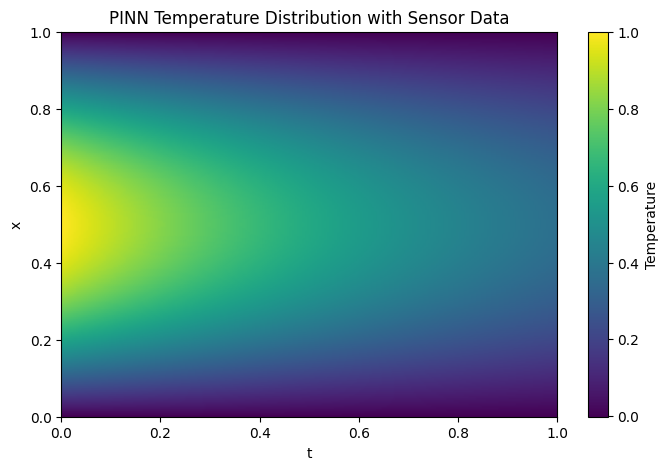

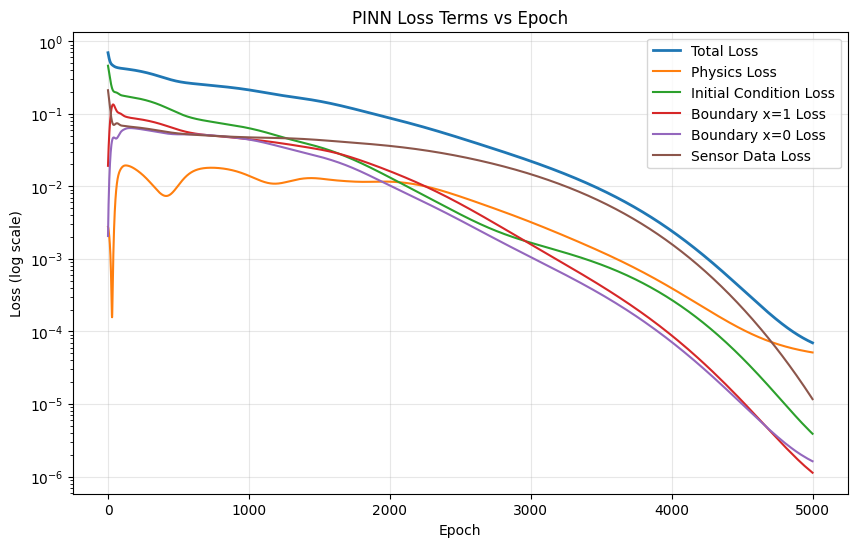

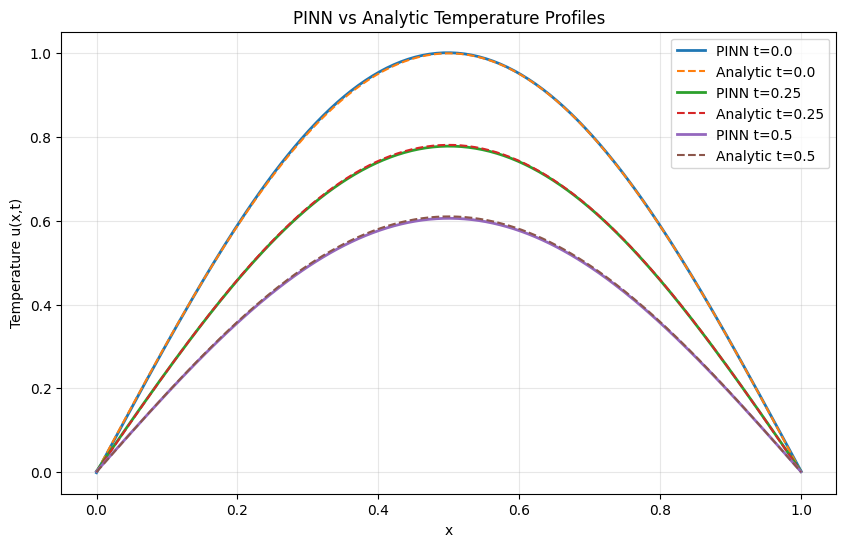


Final learned alpha = 0.102450
True alpha = 0.1



In [ ]:
# @title Fixed Weight PINN for du/dt = -α u_xx with learnable α
lambda_phys   = 1.0 # @param {"type":"number"}
lambda_ic     = 1.0 # @param {"type":"number"}
lambda_bc0    = 1.0 # @param {"type":"number"}
lambda_bc1    = 1.0 # @param {"type":"number"}
lambda_data   = 1.0 # @param {"type":"number"}

import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

device = "cuda" if torch.cuda.is_available() else "cpu"

# ---------------------------------------------------------
# 1. Neural Network for u(x,t)
# ---------------------------------------------------------
class PINN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, 64),
            nn.Tanh(),
            nn.Linear(64, 64),
            nn.Tanh(),
            nn.Linear(64, 1)
        )

    def forward(self, x, t):
        return self.net(torch.cat([x, t], dim=1))

pinn = PINN().to(device)

# ---------------------------------------------------------
# Learnable α
# ---------------------------------------------------------
alpha_true = 0.1  # used for synthetic data only
alpha = torch.nn.Parameter(torch.tensor(0.5, device=device))

optimizer = torch.optim.Adam([
    {"params": pinn.net.parameters(), "lr":1e-4},
    {"params": [alpha], "lr":1e-4}
])

# ---------------------------------------------------------
# 2. Collocation points (physics)
# ---------------------------------------------------------
N_f = 2000
x_f = torch.rand(N_f, 1, device=device)
t_f = torch.rand(N_f, 1, device=device)

# ---------------------------------------------------------
# 3. Initial condition u(x,0) = sin(pi x)
# ---------------------------------------------------------
N_ic = 200
x_ic = torch.rand(N_ic, 1, device=device)
t_ic = torch.zeros_like(x_ic)
u_ic = torch.sin(np.pi * x_ic)

# ---------------------------------------------------------
# 4. Boundary conditions
# ---------------------------------------------------------
N_bc = 200
t_bc = torch.rand(N_bc, 1, device=device)

x_bc1 = torch.ones_like(t_bc)
x_bc0 = torch.zeros_like(t_bc)

# ---------------------------------------------------------
# 5. Real sensor data (synthetic)
# ---------------------------------------------------------
sensor_positions = torch.tensor([0.2, 0.4, 0.6, 0.8], device=device)
sensor_t_raw = torch.rand(300, device=device)

X, T = torch.meshgrid(sensor_positions, sensor_t_raw, indexing='ij')
sensor_x = X.reshape(-1,1)
sensor_t = T.reshape(-1,1)

true_temp = torch.sin(np.pi * sensor_x) * torch.exp(-alpha_true * np.pi**2 * sensor_t)
sensor_u = true_temp

loss_history = {k: [] for k in ["total","phys","ic","bc1","bc0","data"]}

# ---------------------------------------------------------
# 6. Training loop
# ---------------------------------------------------------
def gradients(u, x):
    return torch.autograd.grad(u, x, grad_outputs=torch.ones_like(u),
                               create_graph=True)[0]

for epoch in range(5000):

    x_f.requires_grad_(True)
    t_f.requires_grad_(True)

    u_f = pinn(x_f, t_f)
    u_t = gradients(u_f, t_f)
    u_x = gradients(u_f, x_f)
    u_xx = gradients(u_x, x_f)

    L_phys = (u_t - alpha * u_xx).pow(2).mean()
    L_ic   = (pinn(x_ic, t_ic) - u_ic).pow(2).mean()
    L_bc1  = pinn(x_bc1, t_bc).pow(2).mean()
    L_bc0  = pinn(x_bc0, t_bc).pow(2).mean()

    u_sensor_pred = pinn(sensor_x, sensor_t)
    L_data = (u_sensor_pred - sensor_u).pow(2).mean()

    loss = (lambda_phys*L_phys + lambda_ic*L_ic +
            lambda_bc0*L_bc0 + lambda_bc1*L_bc1 +
            lambda_data*L_data)

    for k,v in zip(["total","phys","ic","bc1","bc0","data"],
                   [loss,L_phys,L_ic,L_bc1,L_bc0,L_data]):
        loss_history[k].append(v.item())

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if epoch % 500 == 0:
        print(f"Epoch {epoch}, Loss={loss.item():.6f}, alpha={alpha.item():.6f}")

# ---------------------------------------------------------
# 8. Evaluate the trained PINN
# ---------------------------------------------------------
x_test = torch.linspace(0, 1, 200, device=device).unsqueeze(1)
t_test = torch.linspace(0, 1, 200, device=device).unsqueeze(1)

X, T = torch.meshgrid(x_test.squeeze(), t_test.squeeze(), indexing='ij')
u_pred = pinn(X.reshape(-1,1), T.reshape(-1,1)).detach().cpu().numpy()
U = u_pred.reshape(200,200)

plt.figure(figsize=(8,5))
plt.imshow(U, extent=[0,1,0,1], origin='lower', aspect='auto')
plt.colorbar(label="Temperature")
plt.xlabel("t")
plt.ylabel("x")
plt.title("PINN Temperature Distribution with Sensor Data")
plt.show()

def plot_loss_terms(loss_history):
    plt.figure(figsize=(10,6))

    plt.plot(loss_history["total"], label="Total Loss", linewidth=2)
    plt.plot(loss_history["phys"], label="Physics Loss")
    plt.plot(loss_history["ic"], label="Initial Condition Loss")
    plt.plot(loss_history["bc1"], label="Boundary x=1 Loss")
    plt.plot(loss_history["bc0"], label="Boundary x=0 Loss")
    plt.plot(loss_history["data"], label="Sensor Data Loss")

    plt.yscale("log")
    plt.xlabel("Epoch")
    plt.ylabel("Loss (log scale)")
    plt.title("PINN Loss Terms vs Epoch")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

plot_loss_terms(loss_history)

#device = next(pinn.parameters()).device

x = torch.linspace(0, 1, 200, device=device).unsqueeze(1)
times=[0.0, 0.25, 0.5]
plt.figure(figsize=(10,6))
for t in times:
    t_tensor = torch.full_like(x, t)

    # PINN prediction
    u_pred = pinn(x, t_tensor).detach().cpu().numpy().flatten()

    # Analytic solution
    u_true = np.sin(np.pi * x.cpu().numpy().flatten()) * np.exp(-alpha_true * np.pi**2 *t)

    # Plot
    plt.plot(x.cpu().numpy(), u_pred, label=f"PINN t={t}", linewidth=2)
    plt.plot(x.cpu().numpy(), u_true, '--', label=f"Analytic t={t}")

plt.xlabel("x")
plt.ylabel("Temperature u(x,t)")
plt.title("PINN vs Analytic Temperature Profiles")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

print("\n====================================")
print(f"Final learned alpha = {alpha.item():.6f}")
print("True alpha =", alpha_true)
print("====================================\n")



Here, we see that the addition of data allowed the PINN to not only learn the unknown *thermal diffusivity* of the system but also provided an excellent estimate of the spatio-temporal temperature field.

This model was trained using data at only four locations, $x=[0.2, 0.4, 0.6, 0.8]$, and at 300 random times between $t=[0, 1.0]$. As shown below, we can still get a pretty good extrapolation of the temperature fields beyond this time, albeit with an overestimation of the temperature decay. *Increasing the weighting of the data may help improve this*.

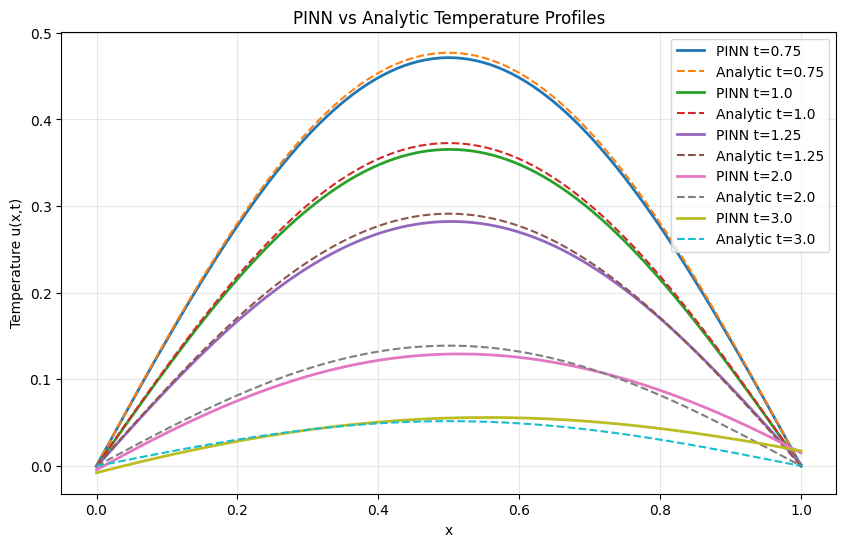

In [ ]:
x = torch.linspace(0, 1, 200, device=device).unsqueeze(1)
times=[0.75, 1.0, 1.25, 2.0, 3.0]
plt.figure(figsize=(10,6))
for t in times:
    t_tensor = torch.full_like(x, t)

    # PINN prediction
    u_pred = pinn(x, t_tensor).detach().cpu().numpy().flatten()

    # Analytic solution
    u_true = np.sin(np.pi * x.cpu().numpy().flatten()) * np.exp(-alpha_true * np.pi**2 *t)

    # Plot
    plt.plot(x.cpu().numpy(), u_pred, label=f"PINN t={t}", linewidth=2)
    plt.plot(x.cpu().numpy(), u_true, '--', label=f"Analytic t={t}")

plt.xlabel("x")
plt.ylabel("Temperature u(x,t)")
plt.title("PINN vs Analytic Temperature Profiles")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

The PINN is only trained on the boundary conditions in the range $t=[0,1.0]$, which leaves the system free to ignore these constraints once we extrapolate beyond the training domain.

***What happens when we have noise in our sensor data?***

One of the primary interests in PINNs comes from the field of data fusion, where we seek to combine simulations with unknown parameters (initial conditions, boundary conditions, or in this case $\alpha$) and imperfect data.

Let's modify our previous example and add $\pm10\%$ random noise to the sensor data. This represents a significant error, especially as much of the temperature has dropped by $t=1.0$ second.

Epoch 0, Loss=1.611136, alpha=0.499900
Epoch 500, Loss=0.367171, alpha=0.551606
Epoch 1000, Loss=0.287475, alpha=0.598002
Epoch 1500, Loss=0.243112, alpha=0.512170
Epoch 2000, Loss=0.202352, alpha=0.421970
Epoch 2500, Loss=0.142963, alpha=0.345703
Epoch 3000, Loss=0.083529, alpha=0.274650
Epoch 3500, Loss=0.042828, alpha=0.212216
Epoch 4000, Loss=0.021522, alpha=0.162326
Epoch 4500, Loss=0.012906, alpha=0.128404
Epoch 5000, Loss=0.010618, alpha=0.109613
Epoch 5500, Loss=0.010240, alpha=0.101724
Epoch 6000, Loss=0.010187, alpha=0.099341
Epoch 6500, Loss=0.010166, alpha=0.098838
Epoch 7000, Loss=0.010150, alpha=0.098778
Epoch 7500, Loss=0.010137, alpha=0.098791
Epoch 8000, Loss=0.010127, alpha=0.098817
Epoch 8500, Loss=0.010120, alpha=0.098847
Epoch 9000, Loss=0.010114, alpha=0.098877
Epoch 9500, Loss=0.010110, alpha=0.098903


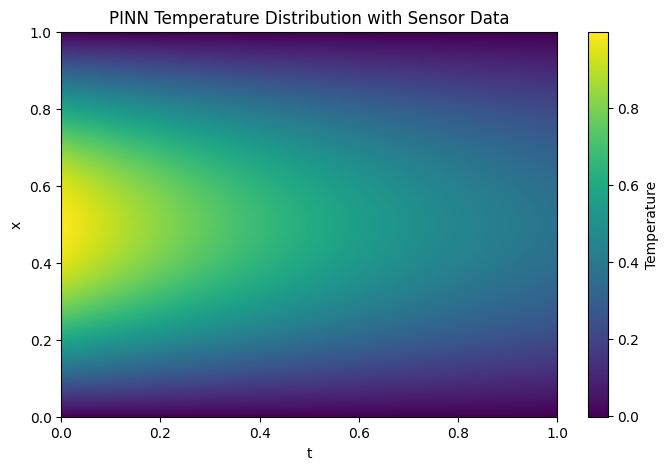

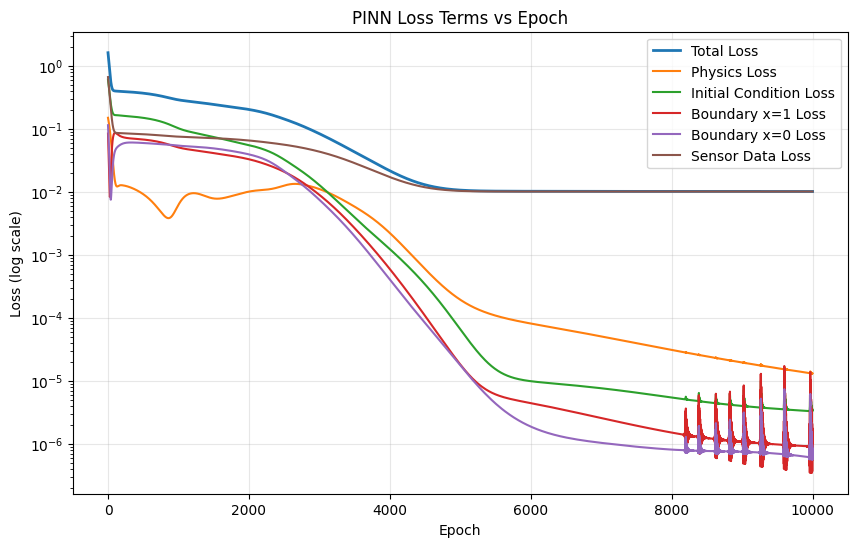

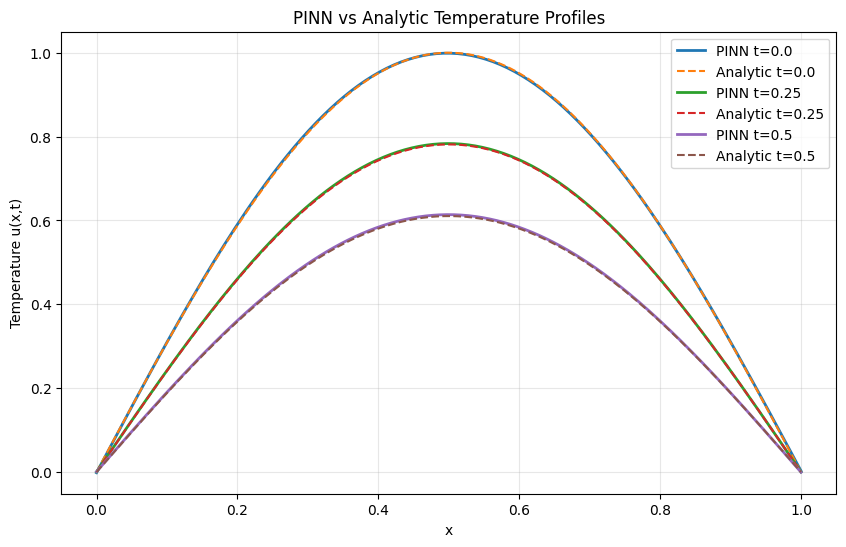


Final learned alpha = 0.098925
True alpha = 0.1



In [ ]:
# @title Fixed Weight PINN for du/dt = -α u_xx with learnable α with data noise
lambda_phys   = 1.0 # @param {"type":"number"}
lambda_ic     = 1.0 # @param {"type":"number"}
lambda_bc0    = 1.0 # @param {"type":"number"}
lambda_bc1    = 1.0 # @param {"type":"number"}
lambda_data   = 1.0 # @param {"type":"number"}
noise_level   = 0.1 # @param {"type":"number"}

import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

device = "cuda" if torch.cuda.is_available() else "cpu"

# ---------------------------------------------------------
# 1. Neural Network for u(x,t)
# ---------------------------------------------------------
class PINN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, 64),
            nn.Tanh(),
            nn.Linear(64, 64),
            nn.Tanh(),
            nn.Linear(64, 1)
        )

    def forward(self, x, t):
        return self.net(torch.cat([x, t], dim=1))

pinn = PINN().to(device)

# ---------------------------------------------------------
# Learnable α
# ---------------------------------------------------------
alpha_true = 0.1  # used for synthetic data only
alpha = torch.nn.Parameter(torch.tensor(0.5, device=device))

optimizer = torch.optim.Adam([
    {"params": pinn.net.parameters(), "lr":1e-4},
    {"params": [alpha], "lr":1e-4}
])

# ---------------------------------------------------------
# 2. Collocation points (physics)
# ---------------------------------------------------------
N_f = 2000
x_f = torch.rand(N_f, 1, device=device)
t_f = torch.rand(N_f, 1, device=device)

# ---------------------------------------------------------
# 3. Initial condition u(x,0) = sin(pi x)
# ---------------------------------------------------------
N_ic = 200
x_ic = torch.rand(N_ic, 1, device=device)
t_ic = torch.zeros_like(x_ic)
u_ic = torch.sin(np.pi * x_ic)

# ---------------------------------------------------------
# 4. Boundary conditions
# ---------------------------------------------------------
N_bc = 200
t_bc = torch.rand(N_bc, 1, device=device)

x_bc1 = torch.ones_like(t_bc)
x_bc0 = torch.zeros_like(t_bc)

# ---------------------------------------------------------
# 5. Real sensor data (synthetic)
# ---------------------------------------------------------
sensor_positions = torch.tensor([0.2, 0.4, 0.6, 0.8], device=device)
sensor_t_raw = torch.rand(300, device=device)

X, T = torch.meshgrid(sensor_positions, sensor_t_raw, indexing='ij')
sensor_x = X.reshape(-1,1)
sensor_t = T.reshape(-1,1)

true_temp = torch.sin(np.pi * sensor_x) * torch.exp(-alpha_true * np.pi**2 * sensor_t)
sensor_u = true_temp + noise_level * torch.randn_like(true_temp)

loss_history = {k: [] for k in ["total","phys","ic","bc1","bc0","data"]}

# ---------------------------------------------------------
# 6. Training loop
# ---------------------------------------------------------
def gradients(u, x):
    return torch.autograd.grad(u, x, grad_outputs=torch.ones_like(u),
                               create_graph=True)[0]

for epoch in range(10000):

    x_f.requires_grad_(True)
    t_f.requires_grad_(True)

    u_f = pinn(x_f, t_f)
    u_t = gradients(u_f, t_f)
    u_x = gradients(u_f, x_f)
    u_xx = gradients(u_x, x_f)

    L_phys = (u_t - alpha * u_xx).pow(2).mean()
    L_ic   = (pinn(x_ic, t_ic) - u_ic).pow(2).mean()
    L_bc1  = pinn(x_bc1, t_bc).pow(2).mean()
    L_bc0  = pinn(x_bc0, t_bc).pow(2).mean()

    u_sensor_pred = pinn(sensor_x, sensor_t)
    L_data = (u_sensor_pred - sensor_u).pow(2).mean()

    loss = (lambda_phys*L_phys + lambda_ic*L_ic +
            lambda_bc0*L_bc0 + lambda_bc1*L_bc1 +
            lambda_data*L_data)

    for k,v in zip(["total","phys","ic","bc1","bc0","data"],
                   [loss,L_phys,L_ic,L_bc1,L_bc0,L_data]):
        loss_history[k].append(v.item())

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if epoch % 500 == 0:
        print(f"Epoch {epoch}, Loss={loss.item():.6f}, alpha={alpha.item():.6f}")

# ---------------------------------------------------------
# 8. Evaluate the trained PINN
# ---------------------------------------------------------
x_test = torch.linspace(0, 1, 200, device=device).unsqueeze(1)
t_test = torch.linspace(0, 1, 200, device=device).unsqueeze(1)

X, T = torch.meshgrid(x_test.squeeze(), t_test.squeeze(), indexing='ij')
u_pred = pinn(X.reshape(-1,1), T.reshape(-1,1)).detach().cpu().numpy()
U = u_pred.reshape(200,200)

plt.figure(figsize=(8,5))
plt.imshow(U, extent=[0,1,0,1], origin='lower', aspect='auto')
plt.colorbar(label="Temperature")
plt.xlabel("t")
plt.ylabel("x")
plt.title("PINN Temperature Distribution with Sensor Data")
plt.show()

def plot_loss_terms(loss_history):
    plt.figure(figsize=(10,6))

    plt.plot(loss_history["total"], label="Total Loss", linewidth=2)
    plt.plot(loss_history["phys"], label="Physics Loss")
    plt.plot(loss_history["ic"], label="Initial Condition Loss")
    plt.plot(loss_history["bc1"], label="Boundary x=1 Loss")
    plt.plot(loss_history["bc0"], label="Boundary x=0 Loss")
    plt.plot(loss_history["data"], label="Sensor Data Loss")

    plt.yscale("log")
    plt.xlabel("Epoch")
    plt.ylabel("Loss (log scale)")
    plt.title("PINN Loss Terms vs Epoch")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

plot_loss_terms(loss_history)

#device = next(pinn.parameters()).device

x = torch.linspace(0, 1, 200, device=device).unsqueeze(1)
times=[0.0, 0.25, 0.5]
plt.figure(figsize=(10,6))
for t in times:
    t_tensor = torch.full_like(x, t)

    # PINN prediction
    u_pred = pinn(x, t_tensor).detach().cpu().numpy().flatten()

    # Analytic solution
    u_true = np.sin(np.pi * x.cpu().numpy().flatten()) * np.exp(-alpha_true * np.pi**2 *t)

    # Plot
    plt.plot(x.cpu().numpy(), u_pred, label=f"PINN t={t}", linewidth=2)
    plt.plot(x.cpu().numpy(), u_true, '--', label=f"Analytic t={t}")

plt.xlabel("x")
plt.ylabel("Temperature u(x,t)")
plt.title("PINN vs Analytic Temperature Profiles")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

print("\n====================================")
print(f"Final learned alpha = {alpha.item():.6f}")
print("True alpha =", alpha_true)
print("====================================\n")



Here, we can see that while the addition of measurement noise required additional training, with loss convergence occurring after 6000 epochs compared to 5000 in the absence of noise.

Even with this noise, the inclusion of physics does a great job of accounting for it. The data loss is naturally higher now, but the PINN is still able to arrive at a pretty good estimate of the true thermal diffusivity of the system.

## 🔗 Bridge to Notebook 10.4

This notebook introduced **Physics-Informed Neural Networks (PINNs)** as a machine learning framework that enables the inclusion of known physical relationships and principles that can help accommodate gaps in physical data or unknown parameters.

You should now understand how a PINN differs from a standard Neural Network and how this can be achieved via the addition of additional loss terms into training.

We explored how to:

*   **Define** a PINN architecture for solving partial differential equations, specifically the heat equation.
*   **Implement** various loss terms, including physics, initial condition, boundary conditions, and data losses.
*   **Analyze** the impact of different loss weightings on PINN training and solution accuracy.
*   **Estimate** unknown physical parameters, such as thermal diffusivity (alpha), directly from data and physics constraints.
*   **Evaluate** the performance of PINNs with and without noisy data.
*   **Visualize** the predicted spatio-temporal temperature fields and the evolution of loss terms during training.

In Notebook 10.4, we will move from ODEs to PDEs, looking at what makes PDEs more challenging to solve and the mathematical nature of different PDEs, before attempting to solve them in Week 11.

#🤖 AI Acknowledgment

MS CoPilot v25.6.440430001 was used to proof read this notebook and provided the Pytorch input code for Neural ODE solver that was used as an example. The code underwent multiple revisions of the methods and neural network inorder to achieve a convergent training.